In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import matplotlib
import scipy.stats as stats
import seaborn as sns
from scipy.stats import spearmanr


In [12]:
df = pd.read_excel("Finalsurvay.xlsx")

In [13]:
gender_counts = df["Gender"].value_counts()

print(gender_counts)

Gender
Female    70
Male      60
Name: count, dtype: int64


In [14]:
gender_percent = gender_counts / gender_counts.sum() * 100

print(gender_percent)

Gender
Female    53.846154
Male      46.153846
Name: count, dtype: float64


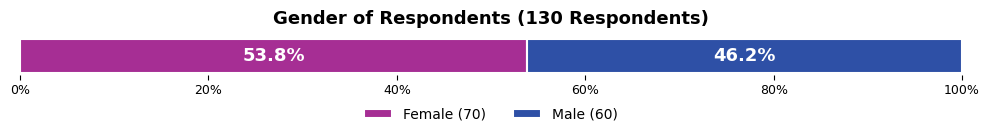

In [15]:
import matplotlib.pyplot as plt

# Get the percentages
female_percent = gender_percent["Female"]
male_percent = gender_percent["Male"]

# Get the numbers
female_n = gender_counts["Female"]
male_n = gender_counts["Male"]
n_respondents = gender_counts.sum()

# Create the figure
fig, ax = plt.subplots(figsize=(10, 2.2))

# Female bar
ax.barh(0, female_percent, color="#A62E94",
        edgecolor="white", linewidth=1.5,
        label=f"Female ({female_n})")

# Male bar (starts right where Female ends — no gap, no overlap)
ax.barh(0, male_percent, left=female_percent, color="#2E50A6",
        edgecolor="white", linewidth=1.5,
        label=f"Male ({male_n})")

# Percentage labels inside each segment
ax.text(female_percent / 2, 0, f"{female_percent:.1f}%",
        ha="center", va="center", color="white", fontsize=13, fontweight="bold")

ax.text(female_percent + male_percent / 2, 0, f"{male_percent:.1f}%",
        ha="center", va="center", color="white", fontsize=13, fontweight="bold")

# X-axis from 0 to 100%
ax.set_xlim(0, 100)
ax.set_xticks(range(0, 101, 20))
ax.set_xticklabels([f"{x}%" for x in range(0, 101, 20)])
ax.tick_params(axis="x", labelsize=9)

# Remove y-axis and all spines for a clean, flat look
ax.set_yticks([])
for spine in ax.spines.values():
    spine.set_visible(False)

# Title
ax.set_title(f"Gender of Respondents ({n_respondents} Respondents)",
             fontweight="bold", fontsize=13, pad=10)

# Legend directly below the chart, close and unobtrusive
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.55),
          ncol=2, frameon=False, fontsize=10)

plt.tight_layout()
plt.show()

In [16]:
df["Age"].value_counts()

Age
21-30       31
Above 60    26
31-40       23
51-60       21
41-50       21
18-20        6
Name: count, dtype: int64

In [17]:
age_counts = df["Age"].value_counts()
age_percent = age_counts / age_counts.sum() * 100

age_summary = pd.DataFrame({
    "n": age_counts,
    "Percent": age_percent
})

age_summary

,n,Percent
Age,,
21-30,31,24.21875
Above 60,26,20.31250
31-40,23,17.96875
51-60,21,16.40625
41-50,21,16.40625
18-20,6,4.68750


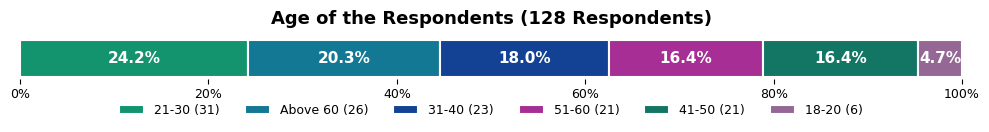

In [18]:
import matplotlib.pyplot as plt
import numpy as np

# Count age categories and calculate percentages
age_counts = df["Age"].value_counts()
age_percent = age_counts / age_counts.sum() * 100
n_respondents = age_counts.sum()

# Colors for each age category (extends automatically if there are
# more categories than the ones listed here)
base_colors = ["#13946F", "#137894", "#134294", "#A62E94", "#137665", "#946794"]
colors = base_colors[:len(age_percent)]
if len(colors) < len(age_percent):
    import matplotlib
    extra = matplotlib.colormaps["tab20"](np.linspace(0, 1, len(age_percent) - len(colors)))
    colors += list(extra)

fig, ax = plt.subplots(figsize=(10, 1.75))

left = 0
for (age, percent), col in zip(age_percent.items(), colors):
    ax.barh(0, percent, left=left, color=col, edgecolor="white", linewidth=1.5,
            label=f"{age} ({age_counts[age]})")
    ax.text(left + percent / 2, 0, f"{percent:.1f}%",
            ha="center", va="center", color="white", fontsize=11, fontweight="bold")
    left += percent

ax.set_xlim(0, 100)
ax.set_xticks(range(0, 101, 20))
ax.set_xticklabels([f"{x}%" for x in range(0, 101, 20)])
ax.tick_params(axis="x", labelsize=9)
ax.set_yticks([])
for spine in ax.spines.values():
    spine.set_visible(False)

ax.set_title(f"Age of the Respondents ({n_respondents} Respondents)",
             fontweight="bold", fontsize=13, pad=10)

ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.35),
          ncol=len(age_percent), frameon=False, fontsize=9)

plt.tight_layout()
plt.show()

In [19]:
df["Household size"].value_counts()

Household size
7 and above    62
4-6            52
1-3            11
Name: count, dtype: int64

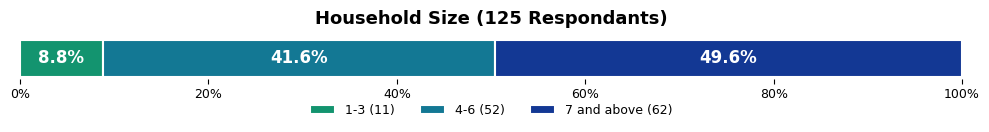

In [20]:
import matplotlib.pyplot as plt

# Set household size category order
household_order = ["1-3", "4-6", "7 and above"]

# Count household size categories in the correct order
household_counts = df["Household size"].value_counts().reindex(household_order)
household_percent = household_counts / household_counts.sum() * 100
n_households = household_counts.sum()

colors = ["#13946F", "#137894", "#133894"]

fig, ax = plt.subplots(figsize=(10, 1.75))

left = 0
for (size, percent), col in zip(household_percent.items(), colors):
    ax.barh(0, percent, left=left, color=col, edgecolor="white", linewidth=1.5,
            label=f"{size} ({household_counts[size]:.0f})")
    ax.text(left + percent / 2, 0, f"{percent:.1f}%",
            ha="center", va="center", color="white", fontsize=12, fontweight="bold")
    left += percent

ax.set_xlim(0, 100)
ax.set_xticks(range(0, 101, 20))
ax.set_xticklabels([f"{x}%" for x in range(0, 101, 20)])
ax.tick_params(axis="x", labelsize=9)
ax.set_yticks([])
for spine in ax.spines.values():
    spine.set_visible(False)

ax.set_title(f"Household Size ({n_households:.0f} Respondants)",
             fontweight="bold", fontsize=13, pad=10)

ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.35),
          ncol=3, frameon=False, fontsize=9)

plt.tight_layout()
plt.show()

In [21]:
supply_counts = df["Water supply frequency"].value_counts()

# Calculate percentages
supply_percent = supply_counts / supply_counts.sum() * 100
supply_counts
supply_percent

Water supply frequency
3-5 days in week    47.328244
1-2 days in week    26.717557
Daily               25.190840
Within two weeks     0.763359
Name: count, dtype: float64

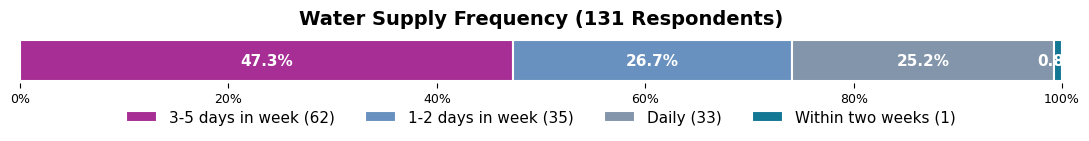

In [22]:
import matplotlib.pyplot as plt

# Set water supply frequency category order
supply_order = [
    "1-2 days in week",
    "3-4 days in week",
    "Within two weeks",
    "Daily"
]

# Count categories in the correct order
supply_counts = df["Water supply frequency"].value_counts()
supply_percent = supply_counts / supply_counts.sum() * 100
n_respondents = supply_counts.sum()

colors = [ "#A62E94" ,"#6991bf","#8395aa", "#137894"]

fig, ax = plt.subplots(figsize=(11, 1.8))

left = 0
for (supply, percent), col in zip(supply_percent.items(), colors):
    ax.barh(0, percent, left=left, color=col, edgecolor="white", linewidth=1.5,
            label=f"{supply} ({supply_counts[supply]:.0f})")
    ax.text(left + percent / 2, 0, f"{percent:.1f}%",
            ha="center", va="center", color="white", fontsize=11, fontweight="bold")
    left += percent

ax.set_xlim(0, 100)
ax.set_xticks(range(0, 101, 20))
ax.set_xticklabels([f"{x}%" for x in range(0, 101, 20)])
ax.tick_params(axis="x", labelsize=9)
ax.set_yticks([])
for spine in ax.spines.values():
    spine.set_visible(False)

ax.set_title(f"Water Supply Frequency ({n_respondents:.0f} Respondents)",
             fontweight="bold", fontsize=14, pad=10)

ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.3),
          ncol=4, frameon=False, fontsize=11)

plt.tight_layout()
plt.show()

In [23]:
df["Interruption duration"].value_counts()

Interruption duration
For 1 week           27
More than 2 weeks     8
For 2 weeks           4
Name: count, dtype: int64

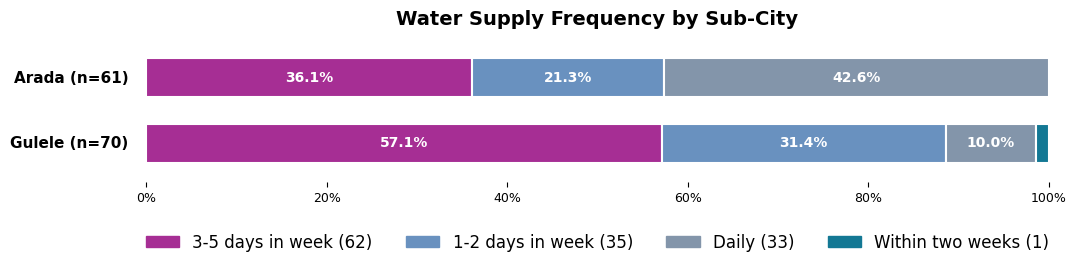

In [24]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

sur = pd.read_excel("Finalsurvay.xlsx")
df = sur.dropna(subset=['Water supply frequency']).copy()

# consistent category -> color mapping, ordered by OVERALL frequency
overall_counts = df['Water supply frequency'].value_counts()
categories = overall_counts.index.tolist()
palette = ["#A62E94", "#6991bf", "#8395aa", "#137894", "#e0a339"]
color_map = dict(zip(categories, palette))

fig, ax = plt.subplots(figsize=(11, 3))
y_positions = {'Arada': 1, 'Gulele': 0}

for subcity, y in y_positions.items():
    sub_df = df[df['Sub-city'] == subcity]
    counts = sub_df['Water supply frequency'].value_counts().reindex(categories, fill_value=0)
    percent = counts / counts.sum() * 100
    n = counts.sum()

    left = 0
    for cat in categories:
        pct = percent[cat]
        if pct == 0:
            continue
        ax.barh(y, pct, left=left, color=color_map[cat], edgecolor="white",
                linewidth=1.5, height=0.6)
        if pct > 4:  # skip labeling tiny slivers to avoid clutter
            ax.text(left + pct/2, y, f"{pct:.1f}%", ha="center", va="center",
                     color="white", fontsize=10, fontweight="bold")
        left += pct
    ax.text(-2, y, f"{subcity} (n={n:.0f})", ha="right", va="center",
             fontsize=11, fontweight="bold")

ax.set_xlim(0, 100)
ax.set_ylim(-0.6, 1.6)
ax.set_xticks(range(0, 101, 20))
ax.set_xticklabels([f"{x}%" for x in range(0, 101, 20)])
ax.tick_params(axis="x", labelsize=9)
ax.set_yticks([])
for spine in ax.spines.values():
    spine.set_visible(False)

ax.set_title("Water Supply Frequency by Sub-City", fontweight="bold", fontsize=14, pad=10)

# build legend from the full category list directly (avoids dropping categories
# that only appear in one sub-city, which ax.get_legend_handles_labels() would miss)
handles = [mpatches.Patch(color=color_map[cat], label=f"{cat} ({int(overall_counts[cat])})")
           for cat in categories]
ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.25),
          ncol=4, frameon=False, fontsize=12)

plt.tight_layout()
plt.show()

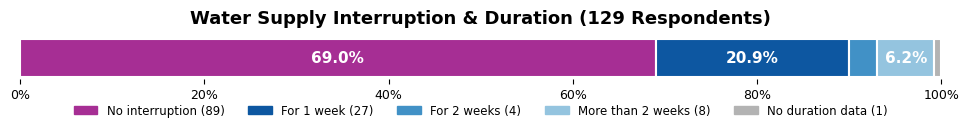

In [25]:

inter_counts = df["Water supply interruption (past month)"].value_counts()
duration_counts = df["Interruption duration"].value_counts()

no_n = int(inter_counts.get("No", 0))
yes_n = int(inter_counts.get("Yes", 0))
n_respondents = no_n + yes_n

# Duration order (edit if your categories differ)
duration_order = ["For 1 week", "For 2 weeks", "More than 2 weeks"]
duration_counts = duration_counts.reindex(duration_order)

# One segment per duration category
duration_segments = [(str(label), int(count)) for label, count in duration_counts.items()
                      if pd.notna(count)]

segments = [("No interruption", no_n)] + duration_segments

# Anything reported as "Yes" but missing a matching duration entry
segment_yes_total = sum(v for _, v in duration_segments)
unspecified = max(yes_n - segment_yes_total, 0)
if unspecified > 0:
    segments.append(("No duration data", unspecified))

# ---------------------------------------------------------------
# Colors: one hue for "No", a different hue for the Yes/duration split
# ---------------------------------------------------------------

no_color = "#A62E94"

blue_cmap = matplotlib.colormaps["Blues"]
duration_shades = list(blue_cmap(np.linspace(0.85, 0.4, len(duration_segments))))
if unspecified > 0:
    duration_shades.append((0.7, 0.7, 0.7, 1.0))  # grey for missing data

colors = [no_color] + duration_shades

# ---------------------------------------------------------------
# Single 100% stacked bar
# ---------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 1.75))

left = 0
for (name, count), col in zip(segments, colors):
    percent = count / n_respondents * 100
    ax.barh(0, percent, left=left, color=col, edgecolor="white", linewidth=1.5)
    if percent >= 4:  # skip label if the sliver is too narrow to read
        ax.text(left + percent / 2, 0, f"{percent:.1f}%",
                ha="center", va="center", color="white", fontsize=11, fontweight="bold")
    left += percent

ax.set_xlim(0, 100)
ax.set_xticks(range(0, 101, 20))
ax.set_xticklabels([f"{x}%" for x in range(0, 101, 20)])
ax.tick_params(axis="x", labelsize=9)
ax.set_yticks([])
for spine in ax.spines.values():
    spine.set_visible(False)

ax.set_title(f"Water Supply Interruption & Duration ({n_respondents} Respondents)",
             fontweight="bold", fontsize=13, pad=10)

legend_labels = [f"{name} ({count})" for name, count in segments]
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=col) for col in colors],
          labels=legend_labels, loc="upper center", bbox_to_anchor=(0.5, -0.35),
          ncol=len(segments), frameon=False, fontsize=8.5)

plt.tight_layout()
plt.show()

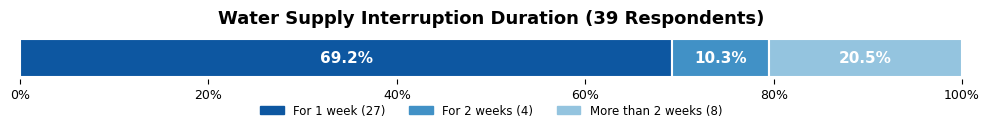

In [26]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

# ---------------------------------------------------------------
# Duration counts only (blank answers are ignored)
# ---------------------------------------------------------------
duration_counts = df["Interruption duration"].dropna().value_counts()

# Preferred order (edit if your categories differ); any other categories go at the end
duration_order = ["For 1 week", "For 2 weeks", "More than 2 weeks"]
ordered = [d for d in duration_order if d in duration_counts.index]
extras = [d for d in duration_counts.index if d not in duration_order]
duration_counts = duration_counts.reindex(ordered + extras)

n_duration = int(duration_counts.sum())   # denominator = respondents with a duration
segments = [(str(label), int(count)) for label, count in duration_counts.items()]

# ---------------------------------------------------------------
# Colors
# ---------------------------------------------------------------
blue_cmap = matplotlib.colormaps["Blues"]
colors = list(blue_cmap(np.linspace(0.85, 0.4, len(segments))))

# ---------------------------------------------------------------
# Single 100% stacked bar
# ---------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 1.75))

left = 0
for (name, count), col in zip(segments, colors):
    percent = count / n_duration * 100
    ax.barh(0, percent, left=left, color=col, edgecolor="white", linewidth=1.5)
    if percent >= 4:  # skip label if the sliver is too narrow to read
        ax.text(left + percent / 2, 0, f"{percent:.1f}%",
                ha="center", va="center", color="white", fontsize=11, fontweight="bold")
    left += percent

ax.set_xlim(0, 100)
ax.set_xticks(range(0, 101, 20))
ax.set_xticklabels([f"{x}%" for x in range(0, 101, 20)])
ax.tick_params(axis="x", labelsize=9)
ax.set_yticks([])
for spine in ax.spines.values():
    spine.set_visible(False)

ax.set_title(f"Water Supply Interruption Duration ({n_duration} Respondents)",
             fontweight="bold", fontsize=13, pad=10)

legend_labels = [f"{name} ({count})" for name, count in segments]
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=col) for col in colors],
          labels=legend_labels, loc="upper center", bbox_to_anchor=(0.5, -0.35),
          ncol=len(segments), frameon=False, fontsize=8.5)

plt.tight_layout()
plt.show()

In [27]:
df["Treats tanker water before drinking"].value_counts()

Treats tanker water before drinking
Yes    19
No      5
Name: count, dtype: int64

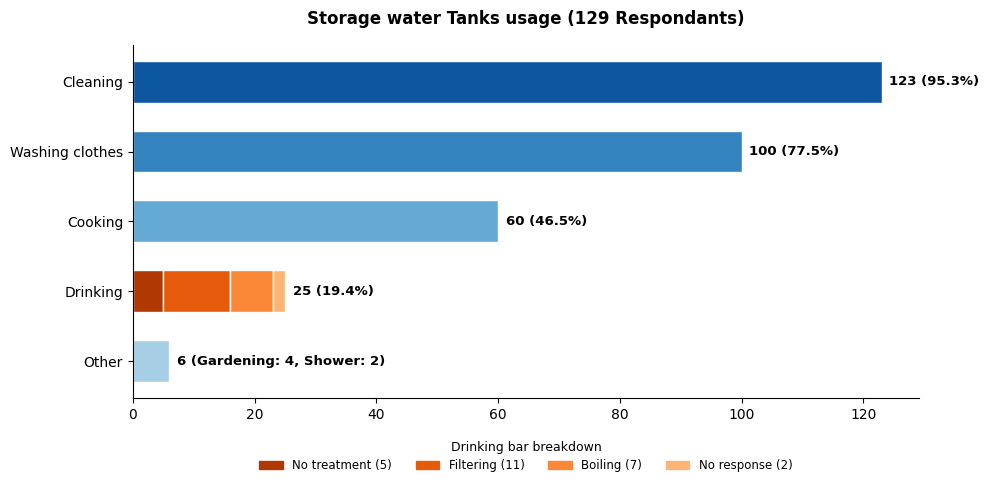

In [28]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import matplotlib

# ---------------------------------------------------------------
# Your analysis code
# ---------------------------------------------------------------

# Make a copy of the column and remove missing values
usage = df["Tanker water usage"].dropna().astype(str)

# Count each individual response
drinking = usage.str.contains("Drinking", case=False, na=False).sum()
cooking = usage.str.contains("Cooking", case=False, na=False).sum()
cleaning = usage.str.contains("Cleaning", case=False, na=False).sum()
washing = usage.str.contains("Washing clothes", case=False, na=False).sum()

# Minor/less common uses get grouped into a single "Other" bar, broken
# down in parentheses in its label (e.g. "Other (Gardening: 4, ...)")
other_labels = ["Gardening", "Shower", "Dishes"]
other_counts = {
    label: usage.str.contains(label, case=False, na=False).sum()
    for label in other_labels
}

# Anything that doesn't match a named category at all also folds into Other
named_pattern = "Drinking|Cooking|Cleaning|Washing clothes|" + "|".join(other_labels)
unmatched = (~usage.str.contains(named_pattern, case=False, na=False)).sum()
if unmatched > 0:
    other_counts["Unspecified"] = unmatched

# Drop any of the "other" sub-categories that had zero responses
other_counts = {k: v for k, v in other_counts.items() if v > 0}
other = sum(other_counts.values())

# Build the label text for the Other bar, e.g. "(Gardening: 4, Shower: 2, Dishes: 1)"
other_breakdown = ", ".join(f"{k}: {v}" for k, v in other_counts.items())

# Counts
usage_counts = {
    "Drinking": drinking,
    "Cooking": cooking,
    "Cleaning": cleaning,
    "Washing clothes": washing,
    "Other": other
}

# Drop categories with zero responses so the chart doesn't show empty bars
usage_counts = {k: v for k, v in usage_counts.items() if v > 0}

# Number of households
n_households = len(usage)

# Calculate percentage of households
usage_percent = {
    category: count / n_households * 100
    for category, count in usage_counts.items()
}

# ---------------------------------------------------------------
# Drinking-water treatment breakdown
# (adjust these column names to match your actual dataframe)
# ---------------------------------------------------------------

treats_counts = df["Treats tanker water before drinking"].value_counts()
method_counts = df["Treatment method"].value_counts()

# "No" segment comes straight from the Treats column
treats_no = treats_counts.get("No", 0)

# Every category that actually appears in Treatment method becomes its own
# segment, using its real label and count exactly as value_counts() reports it
method_segments = [(str(label), int(count)) for label, count in method_counts.items()]

drinking_segments = [("No treatment", int(treats_no))] + method_segments

drinking_segment_total = sum(v for _, v in drinking_segments)
# Anything reported as "Drinking" in the usage column but missing from
# either the Treats or Treatment method columns
unspecified = max(drinking - drinking_segment_total, 0)
if unspecified > 0:
    drinking_segments.append(("No response", unspecified))

# ---------------------------------------------------------------
# Horizontal bar chart: Drinking broken into treatment segments,
# other purposes shown as single solid bars
# ---------------------------------------------------------------

data = [(cat, usage_percent[cat], usage_counts[cat]) for cat in usage_counts]
data.sort(key=lambda x: x[2], reverse=True)

names = [d[0] for d in data]
counts = [d[2] for d in data]
pcts = [d[1] for d in data]

# Single hue (blue) for the non-Drinking purposes
blue_cmap = matplotlib.colormaps["Blues"]
non_drinking = [d for d in data if d[0] != "Drinking"]
blue_shades = blue_cmap(np.linspace(0.85, 0.35, len(non_drinking)))
blue_map = {name: col for (name, _, _), col in zip(non_drinking, blue_shades)}

# A different hue (orange) for the Drinking treatment segments
orange_cmap = matplotlib.colormaps["Oranges"]
drink_shades = orange_cmap(np.linspace(0.85, 0.35, len(drinking_segments)))

fig, ax = plt.subplots(figsize=(10, 5))

y_positions = np.arange(len(names))
y_map = {name: y for name, y in zip(names, y_positions)}
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
for name, pct, cnt in data:
    y = y_map[name]
    if name == "Drinking":
        left = 0
        for (seg_name, seg_val), col in zip(drinking_segments, drink_shades):
            ax.barh(y, seg_val, left=left, height=0.6, color=col, edgecolor="white")
            left += seg_val
        ax.text(left + n_households * 0.01, y, f"{cnt:.0f} ({pct:.1f}%)",
                va="center", ha="left", fontsize=9.5, color="black", fontweight="bold")
    elif name == "Other":
        ax.barh(y, cnt, height=0.6, color=blue_map[name], edgecolor="white")
        ax.text(cnt + n_households * 0.01, y, f"{cnt:.0f} ({other_breakdown})",
                va="center", ha="left", fontsize=9.5, color="black", fontweight="bold")
    else:
        ax.barh(y, cnt, height=0.6, color=blue_map[name], edgecolor="white")
        ax.text(cnt + n_households * 0.01, y, f"{cnt:.0f} ({pct:.1f}%)",
                va="center", ha="left", fontsize=9.5, color="black", fontweight="bold")

# Small legend just for the Drinking segments (colors match the bar)
legend_handles = [plt.Rectangle((0, 0), 1, 1, color=col) for col in drink_shades]
legend_labels = [f"{seg_name} ({seg_val:.0f})" for seg_name, seg_val in drinking_segments]
ax.legend(legend_handles, legend_labels, loc="upper center",
          bbox_to_anchor=(0.5, -0.09), ncol=len(drinking_segments),
          fontsize=8.5, frameon=False, title="Drinking bar breakdown", title_fontsize=9)

ax.set_yticks(y_positions)
ax.set_yticklabels(names, fontsize=10)
ax.invert_yaxis()  # largest bar on top

ax.set_title(f"Storage water Tanks usage ({n_households} Respondants)",
              fontsize=12, fontweight="bold", pad=15)

plt.tight_layout()

plt.show()

In [29]:
df["Tanker cleaning frequency"].value_counts()

Tanker cleaning frequency
never              78
Once a year        17
every two weeks    13
monthly             4
6 month             4
3 month             4
weekly              2
two years           1
2 month             1
Name: count, dtype: int64

In [30]:
df["Tanker cleaned regularly"].value_counts()

Tanker cleaned regularly
No     79
Yes    43
Name: count, dtype: int64

In [31]:
df["Last time tanker cleaned"].value_counts()

Last time tanker cleaned
Before 6 months     8
Before one year     8
Before one month    6
today               1
more than years     1
3 month             1
new                 1
Before one week     1
2 years             1
8 month             1
Name: count, dtype: int64

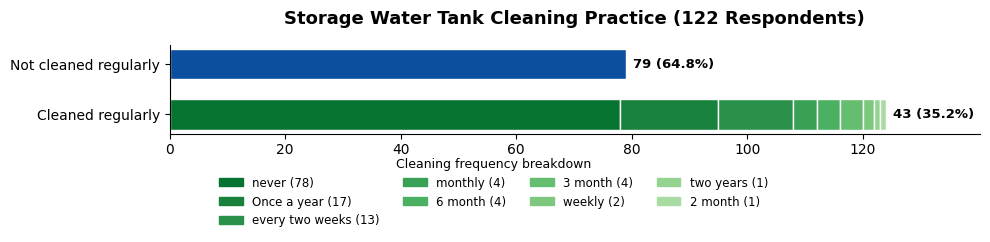

In [32]:



cleaned_counts = df["Tanker cleaned regularly"].value_counts()
frequency_counts = df["Tanker cleaning frequency"].value_counts()

cleaned_no = int(cleaned_counts.get("No", 0))
cleaned_yes = int(cleaned_counts.get("Yes", 0))
n_households = cleaned_no + cleaned_yes

# One segment per frequency category, using its real label and count
frequency_segments = [(str(label), int(count)) for label, count in frequency_counts.items()]

segment_total = sum(v for _, v in frequency_segments)
unspecified = max(cleaned_yes - segment_total, 0)
if unspecified > 0:
    frequency_segments.append(("No response", unspecified))

# ---------------------------------------------------------------
# Colors: solid blue for "No", orange breakdown for "Yes"

# ---------------------------------------------------------------

no_color = "#0B4F9E"
blue_cmap = matplotlib.colormaps["Greens"]
n_colored = len([s for s in frequency_segments if s[0] != "No response"])
freq_shades = list(blue_cmap(np.linspace(0.85, 0.35, n_colored)))
if unspecified > 0:
    freq_shades.append((0.95, 0.8, 0.6, 1.0))  # light tan for missing data

# ---------------------------------------------------------------
# Two rows: "Not cleaned regularly" (solid) and "Cleaned regularly"
# (broken into frequency segments), larger row on top
# ---------------------------------------------------------------

rows = [("Not cleaned regularly", cleaned_no), ("Cleaned regularly", cleaned_yes)]
rows.sort(key=lambda x: x[1], reverse=True)

fig, ax = plt.subplots(figsize=(10, 2.7))

y_positions = np.arange(len(rows))
y_map = {name: y for (name, _), y in zip(rows, y_positions)}

for name, cnt in rows:
    y = y_map[name]
    pct = cnt / n_households * 100
    if name == "Cleaned regularly":
        left = 0
        for (seg_name, seg_val), col in zip(frequency_segments, freq_shades):
            ax.barh(y, seg_val, left=left, height=0.6, color=col, edgecolor="white")
            left += seg_val
        ax.text(left + n_households * 0.01, y, f"{cnt} ({pct:.1f}%)",
                va="center", ha="left", fontsize=9.5, color="black", fontweight="bold")
    else:
        ax.barh(y, cnt, height=0.6, color=no_color, edgecolor="white")
        ax.text(cnt + n_households * 0.01, y, f"{cnt} ({pct:.1f}%)",
                va="center", ha="left", fontsize=9.5, color="black", fontweight="bold")

ax.set_yticks(y_positions)
ax.set_yticklabels([name for name, _ in rows], fontsize=10)
ax.invert_yaxis()

ax.set_xlim(0, n_households * 1.15)
ax.set_xticks(np.arange(0, n_households + 1, 20))
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

ax.set_title(f"Storage Water Tank Cleaning Practice ({n_households} Respondents)",
             fontsize=13, fontweight="bold", pad=15)

legend_handles = [plt.Rectangle((0, 0), 1, 1, color=col) for col in freq_shades]
legend_labels = [f"{seg_name} ({seg_val})" for seg_name, seg_val in frequency_segments]
ax.legend(legend_handles, legend_labels, loc="upper center",
          bbox_to_anchor=(0.4, -0.15), ncol=4,
          fontsize=8.5, frameon=False, title="Cleaning frequency breakdown", title_fontsize=9)

plt.tight_layout()
plt.show()

In [33]:
# Count categories
df["When tanker was installed"].value_counts()


When tanker was installed
Before two years    37
6 years             17
Before one year     13
Before 6 months      9
5 years              7
3 years              5
7 years              4
10 years             3
3 years before       2
20 years             2
12 years             2
8 years              1
Before one month     1
40 years             1
1 year               1
4 years              1
15 years             1
4 year               1
5years               1
Name: count, dtype: int64

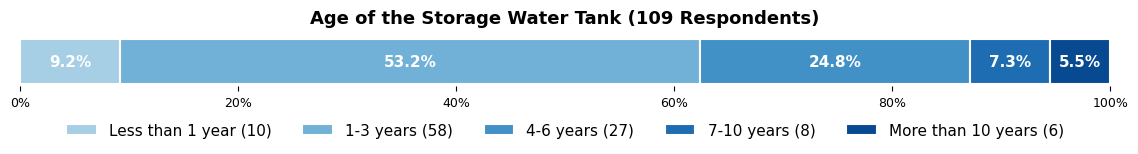

In [34]:

import re

# ---------------------------------------------------------------
# Parse messy free-text age labels into a numeric number of years
# Handles: "Before two years", "6 years before", "Before 6 months",
#          "5 years", digits or number-words, singular/plural, etc.
# ---------------------------------------------------------------

word_to_num = {
    "one": 1, "two": 2, "three": 3, "four": 4, "five": 5,
    "six": 6, "seven": 7, "eight": 8, "nine": 9, "ten": 10,
    "eleven": 11, "twelve": 12, "fifteen": 15, "twenty": 20,
}

def parse_years(label):
    text = str(label).lower().strip()
    digit_match = re.search(r'\d+', text)
    if digit_match:
        num = float(digit_match.group())
    else:
        num = None
        for word, val in word_to_num.items():
            if re.search(rf'\b{word}\b', text):
                num = val
                break
        if num is None:
            return np.nan
    if "month" in text:
        return num / 12
    return num

# Age bins for the tanker (edit thresholds if you want different groupings)
def bin_age(years):
    if pd.isna(years):
        return "Unknown"
    if years < 1:
        return "Less than 1 year"
    elif years <= 3:
        return "1-3 years"
    elif years <= 6:
        return "4-6 years"
    elif years <= 10:
        return "7-10 years"
    else:
        return "More than 10 years"

# ---------------------------------------------------------------
# Apply to the actual column
# ---------------------------------------------------------------

raw_counts = df["When tanker was installed"].value_counts()

binned = {}
for label, count in raw_counts.items():
    category = bin_age(parse_years(label))
    binned[category] = binned.get(category, 0) + int(count)

# Enforce a sensible display order
category_order = ["Less than 1 year", "1-3 years", "4-6 years",
                   "7-10 years", "More than 10 years", "Unknown"]
categories = [c for c in category_order if c in binned]

counts = [binned[c] for c in categories]
n_total = sum(counts)
percents = [c / n_total * 100 for c in counts]

# ---------------------------------------------------------------
# Single-hue gradient: newest -> oldest, light to dark
# ---------------------------------------------------------------

cmap = matplotlib.colormaps["Blues"]
n_colored = len([c for c in categories if c != "Unknown"])
shades = list(cmap(np.linspace(0.35, 0.9, n_colored)))
if "Unknown" in categories:
    shades.append((0.7, 0.7, 0.7, 1.0))  # grey for unparsed/missing

# ---------------------------------------------------------------
# Single 100% stacked bar
# ---------------------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 2.2))

left = 0
for cat, pct, cnt, col in zip(categories, percents, counts, shades):
    ax.barh(0, pct, left=left, color=col, edgecolor="white", linewidth=1.5,
            label=f"{cat} ({cnt})")
    if pct >= 4:
        ax.text(left + pct / 2, 0, f"{pct:.1f}%",
                ha="center", va="center", color="white", fontsize=11, fontweight="bold")
    left += pct

ax.set_xlim(0, 100)
ax.set_xticks(range(0, 101, 20))
ax.set_xticklabels([f"{x}%" for x in range(0, 101, 20)])
ax.tick_params(axis="x", labelsize=9)
ax.set_yticks([])
for spine in ax.spines.values():
    spine.set_visible(False)

ax.set_title(f"Age of the Storage Water Tank ({n_total} Respondents)",
             fontweight="bold", fontsize=13, pad=10)

ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.46),
          ncol=len(categories), frameon=False, fontsize=11)

plt.tight_layout()

plt.show()

In [35]:
excel_file = pd.ExcelFile("cleanclean_phy.xlsx")
df = pd.read_excel(excel_file, sheet_name="Sheet1")
df.columns

Index(['Household/ Condominium', 'sub_city', 'Date', 'Isolate Code',
       'sample_type', 'pH', 'EC', 'TDS', 'Temprature', 'TA_titrant', 'TA',
       'TH titrant', 'TH', 'Turbidity', 'DO', 'Chloride', 'Household ID'],
      dtype='str')

In [36]:
df.columns = df.columns.str.strip()
df.columns

Index(['Household/ Condominium', 'sub_city', 'Date', 'Isolate Code',
       'sample_type', 'pH', 'EC', 'TDS', 'Temprature', 'TA_titrant', 'TA',
       'TH titrant', 'TH', 'Turbidity', 'DO', 'Chloride', 'Household ID'],
      dtype='str')

In [37]:
df = df.rename(columns={
    "Household/ Condominium": "Household_Condominium",
    "Isolate Code": "Isolate_Code", "Temprature":"Temperature",
    "TH titrant":"TH_titrant",
    "TA":"Total Alkalinity",
    "TH":"Total Hardness","DO":
    "Dissolved Oxygen"
 
})
df.columns

Index(['Household_Condominium', 'sub_city', 'Date', 'Isolate_Code',
       'sample_type', 'pH', 'EC', 'TDS', 'Temperature', 'TA_titrant',
       'Total Alkalinity', 'TH_titrant', 'Total Hardness', 'Turbidity',
       'Dissolved Oxygen', 'Chloride', 'Household ID'],
      dtype='str')

In [38]:
physico_cols = [
    "pH",
    "EC",
    "TDS",
    "Temperature",
    "Turbidity",
    "Total Alkalinity",
    "Total Hardness",
    "Dissolved Oxygen",
    "Chloride"
]
physico = df[physico_cols]

In [39]:
summary= pd.DataFrame({
    "n": physico.count(),
    "Mean": physico.mean(),
    "SD": physico.std(),
    "Median": physico.median(),
    "Min": physico.min(),
    "Max": physico.max()
})
summary.round(2)

,n,Mean,SD,Median,Min,Max
pH,262,7.90,0.41,7.95,6.61,10.00
EC,261,123.31,26.07,122.00,94.00,454.00
TDS,261,61.43,12.88,61.00,47.00,225.00
Temperature,261,16.91,2.45,16.90,10.40,27.00
Turbidity,262,0.23,0.97,0.00,0.00,7.00
Total Alkalinity,262,42.10,10.01,37.81,21.89,72.45
Total Hardness,262,54.97,7.78,55.71,35.82,78.84
Dissolved Oxygen,263,6.81,0.28,6.73,6.20,9.43
Chloride,263,11.49,2.04,11.21,6.63,25.48


In [40]:
# Filter only Arada
gulele_df = df[df["sub_city"] == "Gulele"]

# Select only Dissolved Oxygen
gulele_do = gulele_df["Dissolved Oxygen"]

# Descriptive statistics
summary_do_gulele = pd.DataFrame({
    "n": [gulele_do.count()],
    "Mean": [gulele_do.mean()],
    "SD": [gulele_do.std()],
    "Median": [gulele_do.median()],
    "Min": [gulele_do.min()],
    "Max": [gulele_do.max()]
}, index=["DO"])

# Round values
summary_do_gulele = summary_do_gulele.round(2)

summary_do_gulele

,n,Mean,SD,Median,Min,Max
DO,137,6.95,0.32,6.96,6.2,9.43


In [41]:
# Define compliance limits
limits = {
    "pH": {"min": 6.5, "max": 8.5},
    "EC": {"max": 1500},
    "TDS": {"max": 1000},
    "Turbidity": {"max": 5},
    "Total Hardness": {"max": 300},
    "Chloride": {"max": 250}
}

In [42]:
results = []

for parameter, limit in limits.items():
    data = df[parameter].dropna()

    # Check compliance
    if "min" in limit:
        compliant = data.between(limit["min"], limit["max"]).sum()
    else:
        compliant = (data < limit["max"]).sum()
    
    non_compliant = len(data) - compliant
    
    results.append({
        "Parameter": parameter,
        "Limit": (
            f'{limit["min"]}–{limit["max"]}'
            if "min" in limit
            else f'< {limit["max"]}'
        ),
        "Compliant (n)": compliant,
        "Compliant (%)": round(compliant / len(data) * 100, 1),
        "Non-compliant (n)": non_compliant,
        "Non-compliant (%)": round(non_compliant / len(data) * 100, 1),
        "Total (n)": len(data)
    })

compliance_summary = pd.DataFrame(results)

compliance_summary

,Parameter,Limit,Compliant (n),Compliant (%),Non-compliant (n),Non-compliant (%),Total (n)
0,pH,6.5–8.5,257,98.1,5,1.9,262
1,EC,< 1500,261,100.0,0,0.0,261
2,TDS,< 1000,261,100.0,0,0.0,261
3,Turbidity,< 5,258,98.5,4,1.5,262
4,Total Hardness,< 300,262,100.0,0,0.0,262
5,Chloride,< 250,263,100.0,0,0.0,263


In [43]:
from scipy.stats import mannwhitneyu


# Physicochemical parameters to compare
parameters = [
    "pH",
    "EC",
    "TDS",
    "Temperature",
    "Turbidity",
    "Total Alkalinity",
    "Total Hardness",
    "Dissolved Oxygen",
    "Chloride"
]

results = []

for parameter in parameters:

    # Get Tap water values
    tap = df.loc[
        df["sample_type"] == "tap water",
        parameter
    ].dropna()

    # Get tanker water values
    tank = df.loc[
        df["sample_type"] == "tanker water",
        parameter
    ].dropna()

    # Mann–Whitney U test
    stat, p_value = mannwhitneyu(
        tap,
        tank,
        alternative="two-sided"
    )

    results.append({
        "Parameter": parameter,
        "tap water n": len(tap),
        "tap water Median": tap.median(),
        "tap water Mean": tap.mean(),
        "tap water SD": tap.std(),
        "tanker water n": len(tank),
        "tanker water Median": tank.median(),
        "tanker water Mean": tank.mean(),
        "tanker water SD": tank.std(),
        "U statistic": stat,
        "p-value": p_value
    })

# Create results table
mw_results = pd.DataFrame(results)

# Round numerical results


mw_results

,Parameter,tap water n,tap water Median,tap water Mean,tap water SD,tanker water n,tanker water Median,tanker water Mean,tanker water SD,U statistic,p-value
0,pH,126,7.930000,7.863492,0.349583,136,7.990000,7.936985,0.458140,7667.0,0.141683
1,EC,126,120.000000,119.500000,15.182490,135,124.000000,126.866667,32.826273,6858.5,0.006845
2,TDS,126,60.000000,59.603175,7.558920,135,61.000000,63.140741,16.194325,6847.0,0.006461
3,Temperature,126,16.050000,16.500794,2.193609,135,17.400000,17.285185,2.615383,6743.5,0.003832
4,Turbidity,126,0.000000,0.031746,0.250966,136,0.000000,0.419118,1.302733,7688.0,0.001063
5,Total Alkalinity,126,37.806200,41.679687,10.700522,136,39.330000,42.487439,9.346648,7755.5,0.183910
6,Total Hardness,126,56.824650,54.684923,7.696478,136,55.714400,55.233239,7.868992,8375.0,0.752891
7,Dissolved Oxygen,126,6.755000,6.832063,0.315879,137,6.720000,6.788394,0.245735,9335.0,0.253501
8,Chloride,126,10.558887,11.397592,1.902172,137,11.212209,11.584501,2.161473,8107.0,0.390880


In [44]:

# Filter only Gulele
gulele_df = df[df["sub_city"] == "Gulele"]

# Get DO values for each sample type
tap_do = gulele_df.loc[
    gulele_df["sample_type"] == "tap water",
    "Dissolved Oxygen"
].dropna()

tank_do = gulele_df.loc[
    gulele_df["sample_type"] == "tanker water",
    "Dissolved Oxygen"
].dropna()

# Mann–Whitney U test
U, p_value = mannwhitneyu(
    tap_do,
    tank_do,
    alternative="two-sided"
)
do_results = pd.DataFrame({
    "Parameter": ["Dissolved Oxygen"],
    "Tap n": [len(tap_do)],
    "Tap Mean": [tap_do.mean()],
    "Tap SD": [tap_do.std()],
    "Tap Median": [tap_do.median()],
    "Tank n": [len(tank_do)],
    "Tank Mean": [tank_do.mean()],
    "Tank SD": [tank_do.std()],
    "Tank Median": [tank_do.median()],
    "U statistic": [U],
    "p-value": [p_value]
}).round

do_results


<bound method DataFrame.round of           Parameter  Tap n  Tap Mean    Tap SD  Tap Median  Tank n  Tank Mean  \
0  Dissolved Oxygen     66  6.993939  0.359221        6.98      71   6.909577   

    Tank SD  Tank Median  U statistic   p-value  
0  0.284818         6.91       2828.5  0.036634  >

In [45]:

parameters = [
    "pH",
    "EC",
    "TDS",
    "Temperature",
    "Turbidity",
    "Total Alkalinity",
    "Total Hardness",
    "Chloride"
]

results = []

for parameter in parameters:

    # Arada data
    arada = df.loc[
        df["sub_city"] == "Arada",
        parameter
    ].dropna()

    # Gulele data
    gulele = df.loc[
        df["sub_city"] == "Gulele",
        parameter
    ].dropna()

    # Mann–Whitney U test
    U, p_value = mannwhitneyu(
        arada,
        gulele,
        alternative="two-sided"
    )

    results.append({
        "Parameter": parameter,
        
        "Arada n": len(arada),
        "Arada Mean": arada.mean(),
        "Arada SD": arada.std(),
        "Arada Median": arada.median(),
        
        "Gulele n": len(gulele),
        "Gulele Mean": gulele.mean(),
        "Gulele SD": gulele.std(),
        "Gulele Median": gulele.median(),
        
        "U statistic": U,
        "p-value": p_value
    })

# Create results table
arada_gulele_results = pd.DataFrame(results).round(3)

arada_gulele_results

,Parameter,Arada n,Arada Mean,Arada SD,Arada Median,Gulele n,Gulele Mean,Gulele SD,Gulele Median,U statistic,p-value
0,pH,126,8.059,0.342,8.070,136,7.756,0.416,7.825,12648.5,0.000
1,EC,126,126.119,35.987,124.000,135,120.689,9.827,120.000,9233.5,0.232
2,TDS,126,62.365,17.839,61.000,135,60.563,4.819,60.000,8396.0,0.859
3,Temperature,126,17.437,2.380,17.900,135,16.411,2.415,16.000,11206.5,0.000
4,Turbidity,126,0.127,0.704,0.000,136,0.331,1.161,0.000,8086.5,0.073
5,Total Alkalinity,126,47.134,11.877,41.400,136,37.435,4.185,37.806,11985.0,0.000
6,Total Hardness,126,49.840,6.212,50.242,136,59.722,5.820,61.320,1932.0,0.000
7,Chloride,126,11.459,2.377,10.193,137,11.528,1.679,11.216,7056.0,0.010


In [46]:
import seaborn as sns

C:\Users\elsab\AppData\Local\Temp\ipykernel_7656\2695797782.py:59: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\elsab\AppData\Local\Temp\ipykernel_7656\2695797782.py:59: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\elsab\AppData\Local\Temp\ipykernel_7656\2695797782.py:59: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\elsab\AppData\Local\Temp\ipykernel_7656\2695797782.py:59: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` 

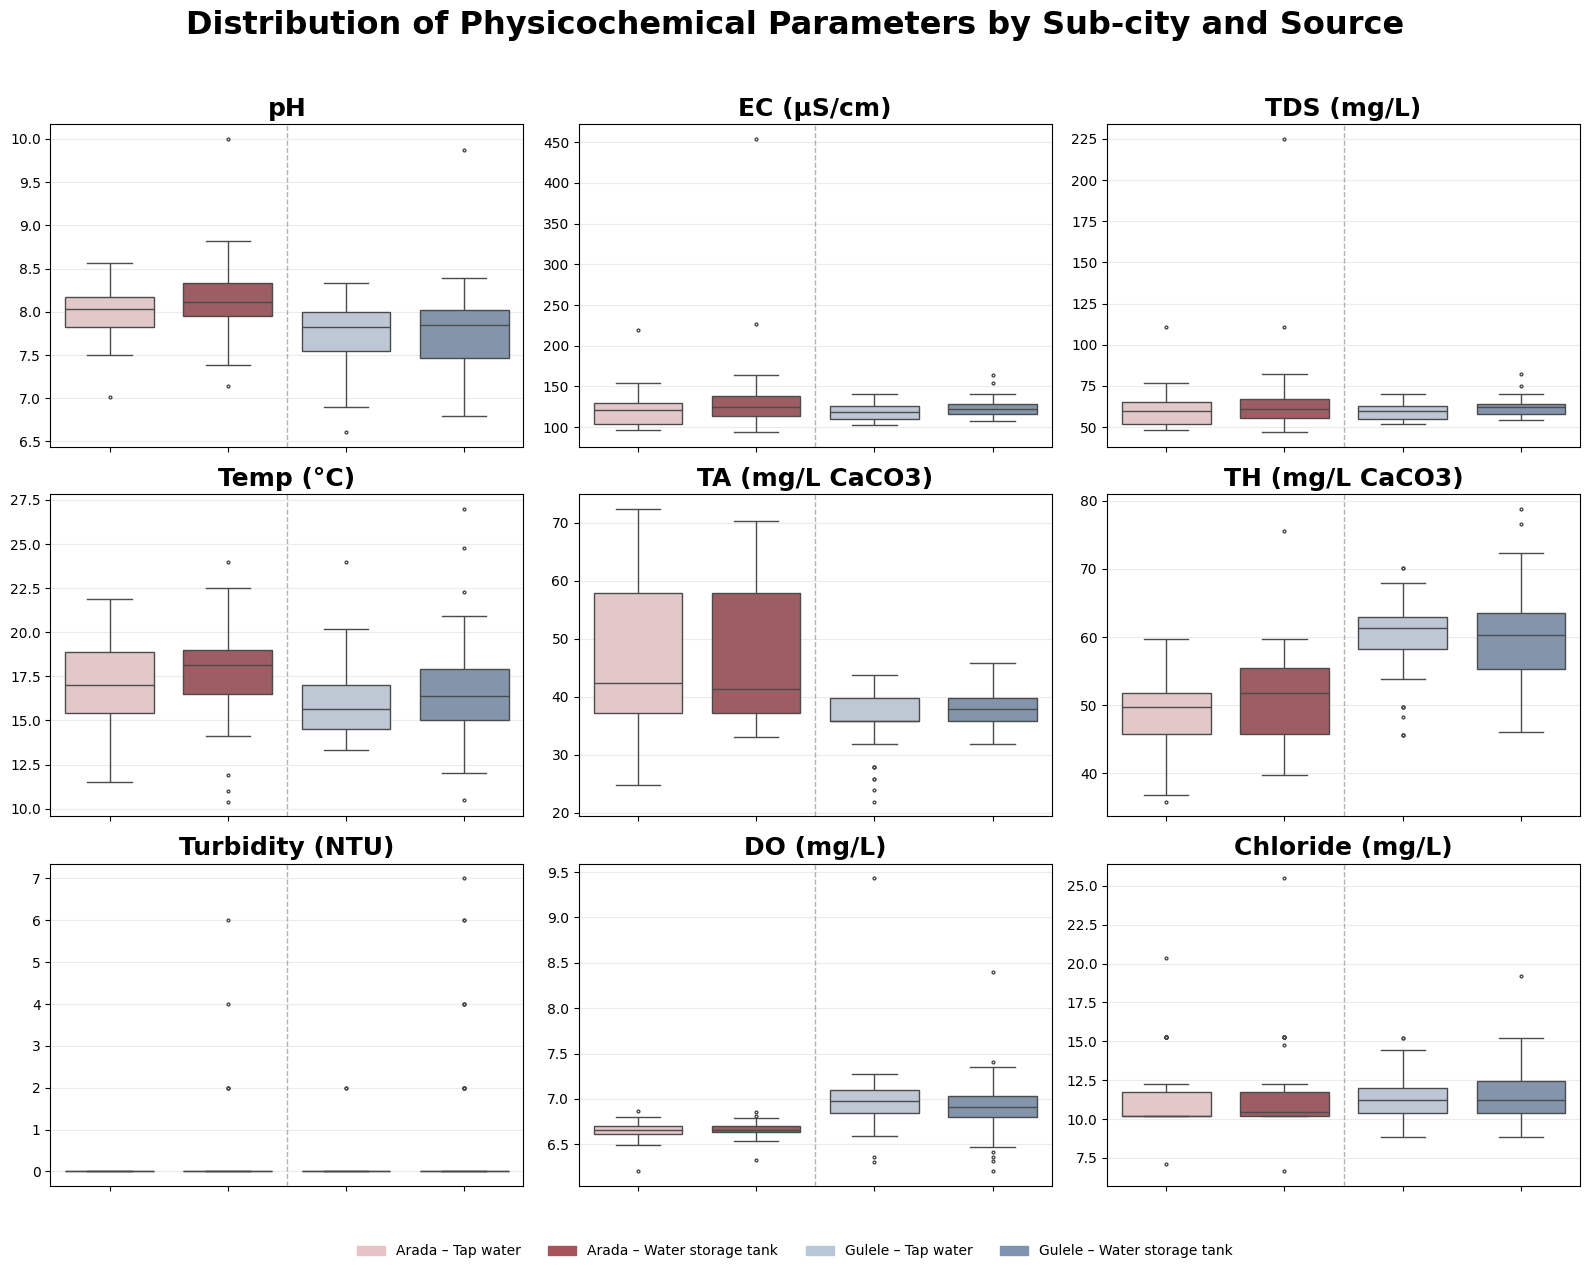

In [47]:
import matplotlib.patches as mpatches
# -----------------------------
# Parameters to plot
# -----------------------------
parameters = [
    ("pH", "pH"),
    ("EC", "EC (µS/cm)"),
    ("TDS", "TDS (mg/L)"),
    ("Temperature", "Temp (°C)"),
    ("Total Alkalinity", "TA (mg/L CaCO3)"),
    ("Total Hardness", "TH (mg/L CaCO3)"),
    ("Turbidity", "Turbidity (NTU)"),
    ("Dissolved Oxygen", "DO (mg/L)"),
    ("Chloride", "Chloride (mg/L)")
]

# -----------------------------
# Create combined group variable
# -----------------------------
df["Group"] = (
    df["sub_city"].astype(str) + "_" +
    df["sample_type"].astype(str)
)

group_order = [
    "Arada_tap water",
    "Arada_tanker water",
    "Gulele_tap water",
    "Gulele_tanker water"
]


# -----------------------------
# Create figure
# -----------------------------
fig, axes = plt.subplots(
    3,
    3,
    figsize=(16, 13)
)

axes = axes.flatten()

# Colors:
# Arada = red shades
# Gulele = blue shades
colors = [
    "#e8c3c5",
    "#a6545a",
    "#b9c8d8",
    "#7d94b0"
]

# -----------------------------
# Create boxplots
# -----------------------------
for ax, (parameter, title) in zip(axes, parameters):

    sns.boxplot(
        data=df,
        x="Group",
        y=parameter,
        order=group_order,
        palette=colors,
        width=0.75,
        linewidth=1,
        fliersize=2,
        ax=ax
    )

    # Title
    ax.set_title(
        title,
        fontsize=18,
        fontweight="bold"
    )
    ax.set_xticklabels([])
    ax.set_xlabel("")

    # Remove axis labels
    ax.set_xlabel("")
    ax.set_ylabel("")

    # Dashed line between Arada and Gulele
    ax.axvline(
        x=1.5,
        color="gray",
        linestyle="--",
        linewidth=1,
        alpha=0.6
    )

    # Light horizontal grid
    ax.grid(
        axis="y",
        linestyle="-",
        alpha=0.25
    )

    ax.set_axisbelow(True)
# -----------------------------
# Legend at the bottom
# -----------------------------
legend_labels = [
    "Arada – Tap water",
    "Arada – Water storage tank",
    "Gulele – Tap water",
    "Gulele – Water storage tank"
]

legend_handles = [
    mpatches.Patch(color=colors[i], label=legend_labels[i])
    for i in range(4)
]

fig.legend(
    handles=legend_handles,
    loc="lower center",
    ncol=4,
    frameon=False,
    fontsize=10,
    bbox_to_anchor=(0.5, 0.01)
)

# -----------------------------
# Main title
# -----------------------------
fig.suptitle(
    "Distribution of Physicochemical Parameters by Sub-city and Source",
    fontsize=23,
    fontweight="bold",
    y=0.98
)

plt.tight_layout(
    rect=[0, 0.06, 1, 0.96]
)

plt.show()

In [48]:
parameters = [
    "pH",
    "EC",
    "TDS",
    "Temperature",
    "Total Alkalinity",
    "Total Hardness",
    "Turbidity",
    "Dissolved Oxygen",
    "Chloride"
]

labels = [
    "pH",
    "EC",
    "TDS",
    "Temperature",
    "TA",
    "TH",
    "Turbidity",
    "DO",
    "Chloride"
]

In [49]:
import seaborn as sns
from scipy.stats import spearmanr
data = df[parameters]

corr = data.corr(method="spearman")

# Create empty matrices
corr = pd.DataFrame(
    np.nan,
    index=parameters,
    columns=parameters
)

p_values = pd.DataFrame(
    np.nan,
    index=parameters,
    columns=parameters
)

# Loop through parameter pairs
for i, var1 in enumerate(parameters):
    for j, var2 in enumerate(parameters):

        # If either variable is DO, use only Gulele data
        if var1 == "Dissolved Oxygen" or var2 == "Dissolved Oxygen":
            subset = df[df["sub_city"] == "Gulele"][
                [var1, var2]
            ].dropna()

        # Otherwise, use all available data
        else:
            subset = df[[var1, var2]].dropna()
# Calculate correlation
        if len(subset) >= 3:

            rho, p = spearmanr(
                subset.iloc[:, 0],
                subset.iloc[:, 1]
            )

            corr.loc[var1, var2] = rho
            p_values.loc[var1, var2] = p


corr

,pH,EC,TDS,Temperature,Total Alkalinity,Total Hardness,Turbidity,Dissolved Oxygen,Chloride
pH,1.000000,-0.211926,-0.175754,0.102670,0.429918,-0.472200,0.020093,0.156701,0.000716
EC,-0.211926,1.000000,0.922087,0.397633,-0.419164,0.260003,0.055146,-0.242866,0.015576
TDS,-0.175754,0.922087,1.000000,0.351319,-0.405595,0.306130,0.064326,-0.249813,0.055728
Temperature,0.102670,0.397633,0.351319,1.000000,-0.003673,-0.131489,-0.037305,-0.121502,-0.137171
Total Alkalinity,0.429918,-0.419164,-0.405595,-0.003673,1.000000,-0.449734,-0.045456,0.091565,-0.036655
Total Hardness,-0.472200,0.260003,0.306130,-0.131489,-0.449734,1.000000,0.129568,-0.196826,0.214071
Turbidity,0.020093,0.055146,0.064326,-0.037305,-0.045456,0.129568,1.000000,-0.049771,-0.041382
Dissolved Oxygen,0.156701,-0.242866,-0.249813,-0.121502,0.091565,-0.196826,-0.049771,1.000000,-0.014847
Chloride,0.000716,0.015576,0.055728,-0.137171,-0.036655,0.214071,-0.041382,-0.014847,1.000000


In [50]:
annotations = corr.copy().astype(str)

for i in range(len(parameters)):
    for j in range(len(parameters)):

        rho = corr.iloc[i, j]
        p = p_values.iloc[i, j]

        # Diagonal: show only 1.00, without stars
        if i == j:
            annotations.iloc[i, j] = f"{rho:.2f}"
            continue

        # Add significance stars for other correlations
        if p < 0.001:
            stars = "***"
        elif p < 0.01:
            stars = "**"
        elif p < 0.05:
            stars = "*"
        else:
            stars = ""

        annotations.iloc[i, j] = f"{rho:.2f}{stars}"

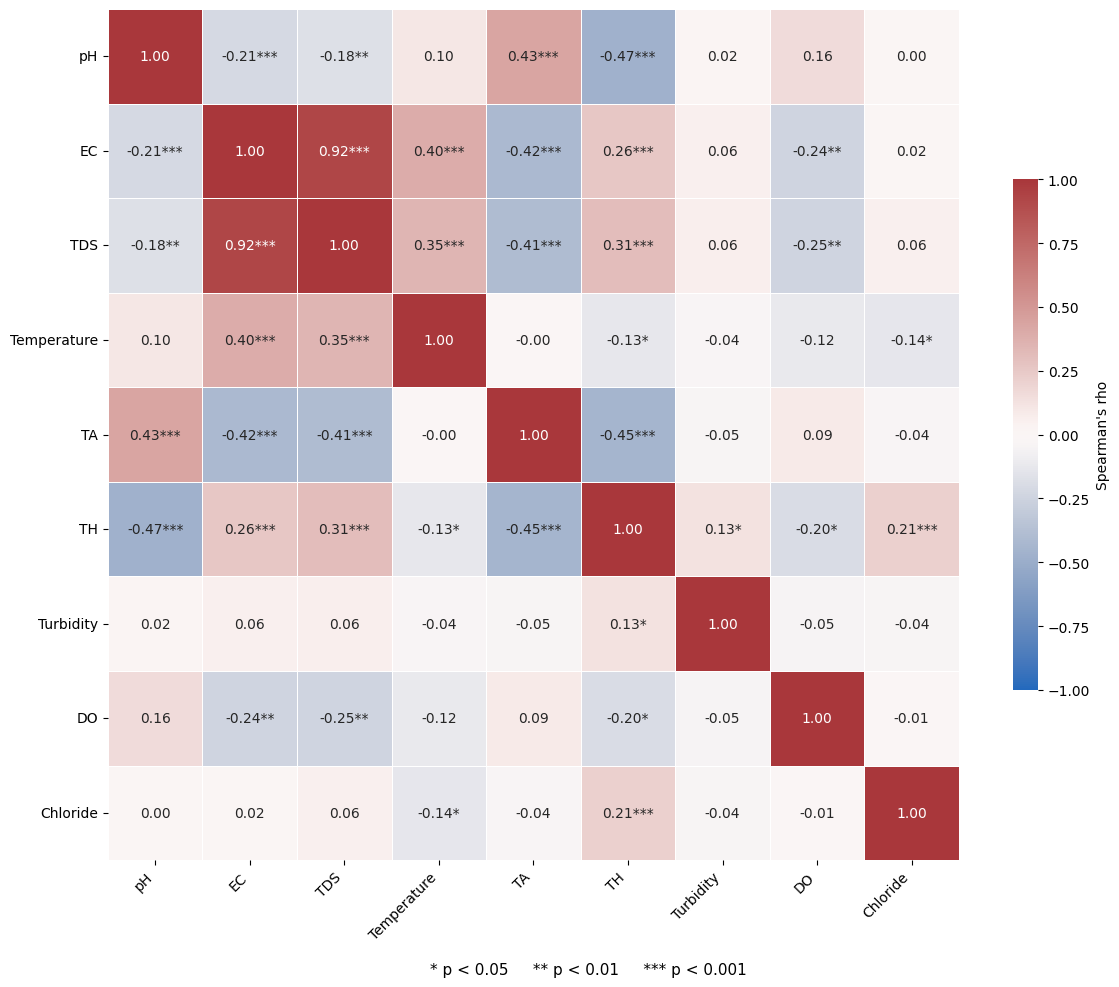

In [51]:
plt.figure(figsize=(12, 10))

sns.heatmap(
    corr,
    annot=annotations,
    fmt="",
    cmap="vlag",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    linecolor="white",
    cbar_kws={
        "label": "Spearman's rho",
        "shrink": 0.6
    },
    xticklabels=labels,
    yticklabels=labels
)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.figtext(
    0.5,
    0.02,
    "* p < 0.05     ** p < 0.01     *** p < 0.001",
    ha="center",
    fontsize=11
)

plt.tight_layout(
    rect=[0, 0.05, 1, 1]
)

plt.show()

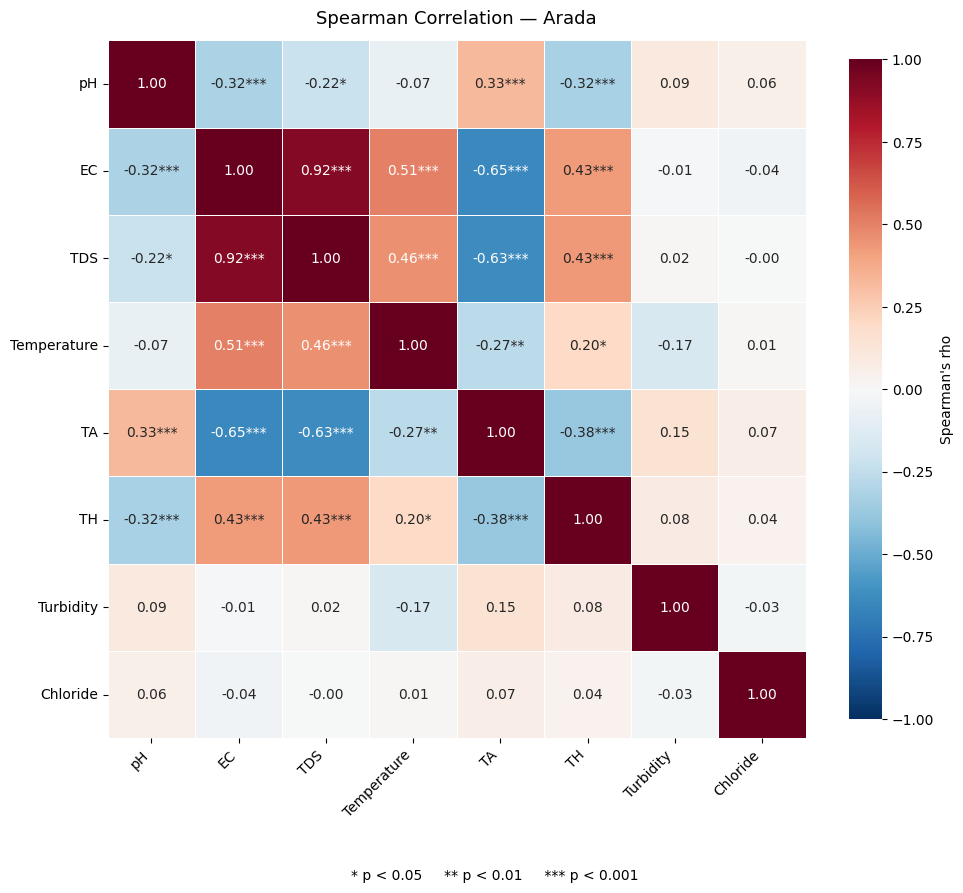

Saved: spearman_correlation_Arada.png


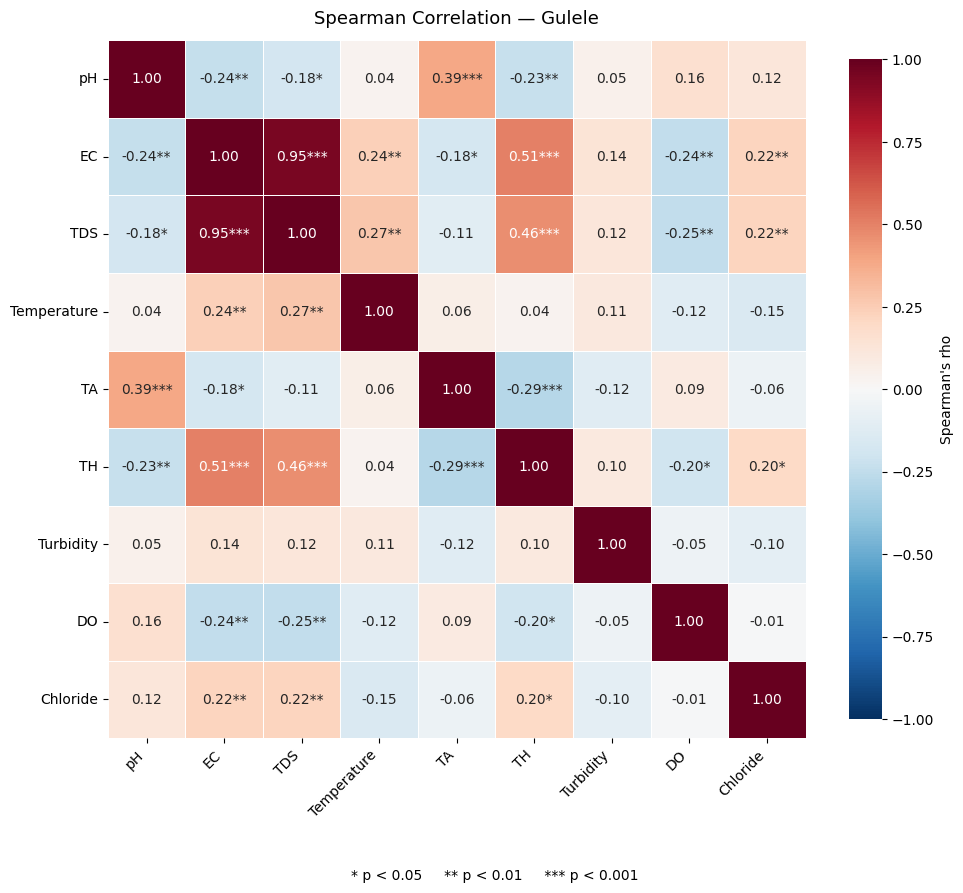

Saved: spearman_correlation_Gulele.png


In [52]:

RAW_COL = {
    "pH": "pH",
    "EC": "EC",
    "TDS": "TDS",
    "Temperature": "Temperature",
    "TA": "Total Alkalinity",
    "TH": "Total Hardness",
    "Turbidity": "Turbidity",
    "DO": "Dissolved Oxygen",
    "Chloride": "Chloride",
}

SUBCITY_COL = "sub_city"

# ------------------------------------------------------------------
# 3. Helper: Spearman correlation matrix + significance stars
# ------------------------------------------------------------------
def spearman_with_stars(data: pd.DataFrame):
    """Return (rho_matrix, star_matrix) as DataFrames for the given data."""
    cols = data.columns
    n = len(cols)
    rho = pd.DataFrame(np.eye(n), index=cols, columns=cols)
    stars = pd.DataFrame("", index=cols, columns=cols)

    for i in range(n):
        for j in range(n):
            if i == j:
                stars.iloc[i, j] = ""
                continue
            x = data.iloc[:, i]
            y = data.iloc[:, j]
            valid = x.notna() & y.notna()
            if valid.sum() < 3:
                rho.iloc[i, j] = np.nan
                continue
            r, p = spearmanr(x[valid], y[valid])
            rho.iloc[i, j] = r
            if p < 0.001:
                stars.iloc[i, j] = "***"
            elif p < 0.01:
                stars.iloc[i, j] = "**"
            elif p < 0.05:
                stars.iloc[i, j] = "*"
            else:
                stars.iloc[i, j] = ""
    return rho, stars


def plot_corr_heatmap(rho, stars, title, out_path):
    labels = rho.index.tolist()
    annot = rho.copy().astype(object)
    for i in range(len(labels)):
        for j in range(len(labels)):
            annot.iloc[i, j] = f"{rho.iloc[i, j]:.2f}{stars.iloc[i, j]}"

    fig, ax = plt.subplots(figsize=(10, 9))
    sns.heatmap(
        rho,
        annot=annot,
        fmt="",
        cmap="RdBu_r",
        vmin=-1, vmax=1,
        square=True,
        linewidths=0.5,
        linecolor="white",
        cbar_kws={"label": "Spearman's rho", "shrink": 0.8},
        annot_kws={"size": 10},
        ax=ax,
    )
    ax.set_xticklabels(labels, rotation=45, ha="right")
    ax.set_yticklabels(labels, rotation=0)
    ax.set_title(title, fontsize=13, pad=12)

    fig.text(
        0.5, -0.02,
        "* p < 0.05     ** p < 0.01     *** p < 0.001",
        ha="center", fontsize=10,
    )
    plt.tight_layout()
  
    plt.show()
    print(f"Saved: {out_path}")


# ------------------------------------------------------------------
# 4. Run per sub-city
# ------------------------------------------------------------------
subcities = df[SUBCITY_COL].dropna().unique()

for city in subcities:
    subset = df[df[SUBCITY_COL] == city].copy()

    # Build the column set for this sub-city; drop DO for Arada
    cols_to_use = dict(RAW_COL)
    if str(city).strip().lower() == "arada":
        cols_to_use.pop("DO", None)

    # Select and coerce to numeric
    data = subset[[cols_to_use[k] for k in cols_to_use]].apply(
        pd.to_numeric, errors="coerce"
    )
    data.columns = list(cols_to_use.keys())  # rename to short labels

    rho, stars = spearman_with_stars(data)

    out_path = f"spearman_correlation_{str(city).strip().replace(' ', '_')}.png"
    plot_corr_heatmap(rho, stars, f"Spearman Correlation — {city}", out_path)

In [53]:
from sklearn.preprocessing import StandardScaler

In [54]:
# Load the Excel file
file_path = "biofilmFINAL_clean.xlsx"

# Read the Excel sheet
df = pd.read_excel(file_path)
print(df["sample_type"].value_counts(dropna=False))
# Check the column names
print(df["sample_type"].unique())


sample_type
Biofilm swab    416
Tanker Water    354
Tap Water       240
Name: count, dtype: int64
<StringArray>
['Biofilm swab', 'Tanker Water', 'Tap Water']
Length: 3, dtype: str


Index(['Sample ID', 'Household ID', 'Sample Code', 'sample_type', 'Sub City',
       'Site Type', 'Tank', 'Plate', 'Position', 'OD 1', 'OD 2', 'Mean OD',
       'Normalized OD', 'OD - ODc', 'NC', 'NC Mean', 'NC SD', 'ODc (Cutoff)',
       '2×ODc (Weak)', '4×ODc (Moderate)', 'Category'],
      dtype='str')


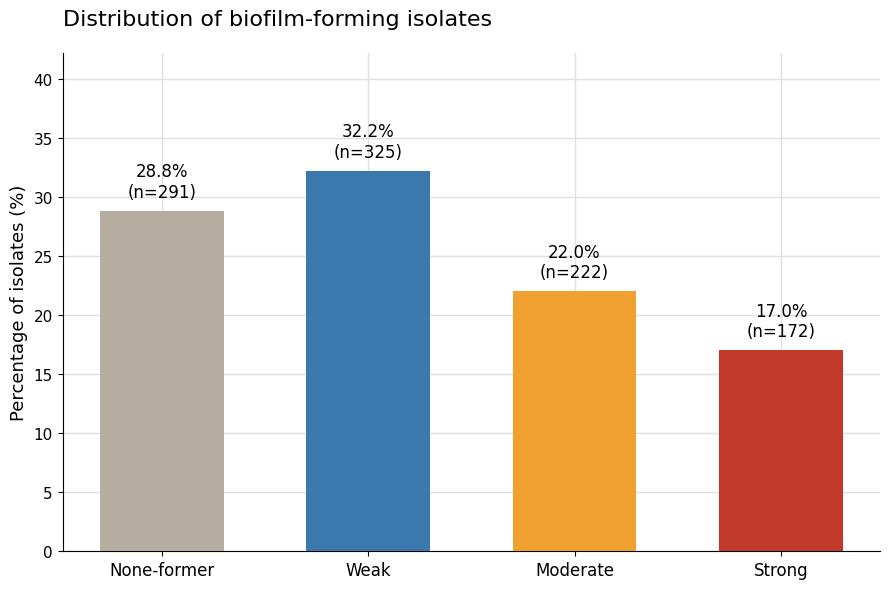

In [55]:

# Load the Excel file
file_path = "biofilmFINAL_clean.xlsx"

# Read the Excel sheet
df = pd.read_excel(file_path)

# Check the column names
print(df.columns)

# Replace "Biofilm_Category" with the actual name of your category column
category_col = "Category"

# Count each category
category_counts = df[category_col].value_counts()

# Set the desired order (using "None-former" to match the reference chart's label)
order = ["None-former", "Weak", "Moderate", "Strong"]
category_counts = category_counts.reindex(order)

# Convert counts to percentages
total = category_counts.sum()
percentages = (category_counts / total * 100).round(1)

# Colors matching the reference image
colors = ["#b5aea0", "#3b78ae", "#f0a02f", "#c0392b"]

# Create bar chart
fig, ax = plt.subplots(figsize=(9, 6))
bars = ax.bar(
    category_counts.index,
    percentages.values,
    color=colors,
    width=0.6,
    zorder=3
)

# Add horizontal gridlines behind the bars (light, y-axis only)
ax.yaxis.grid(True, color="#e0e0e0", linewidth=1, zorder=0)
ax.set_axisbelow(True)

# Add faint vertical guide lines from each bar up to the top of the plot
ymax = max(41, percentages.max() + 10)
for bar in bars:
    x_center = bar.get_x() + bar.get_width() / 2
    ax.plot([x_center, x_center], [bar.get_height(), ymax],
             color="#e0e0e0", linewidth=1, zorder=1)

# Add percentage + count labels above each bar
for bar, pct, count in zip(bars, percentages.values, category_counts.values):
    label = f"{pct}%\n(n={count})"
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + (ymax * 0.02),
        label,
        ha="center",
        va="bottom",
        fontsize=12
    )

# Remove top/right/left spines for a cleaner look
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

# Labels and title
ax.set_ylabel("Percentage of isolates (%)", fontsize=13)
ax.set_xlabel("")
ax.set_title("Distribution of biofilm-forming isolates", fontsize=16, loc="left", pad=20)

ax.set_ylim(0, ymax)
ax.tick_params(axis="x", labelsize=12)
ax.tick_params(axis="y", labelsize=11)

plt.tight_layout()
plt.show()

In [56]:
print(df.columns)

Index(['Sample ID', 'Household ID', 'Sample Code', 'sample_type', 'Sub City',
       'Site Type', 'Tank', 'Plate', 'Position', 'OD 1', 'OD 2', 'Mean OD',
       'Normalized OD', 'OD - ODc', 'NC', 'NC Mean', 'NC SD', 'ODc (Cutoff)',
       '2×ODc (Weak)', '4×ODc (Moderate)', 'Category'],
      dtype='str')


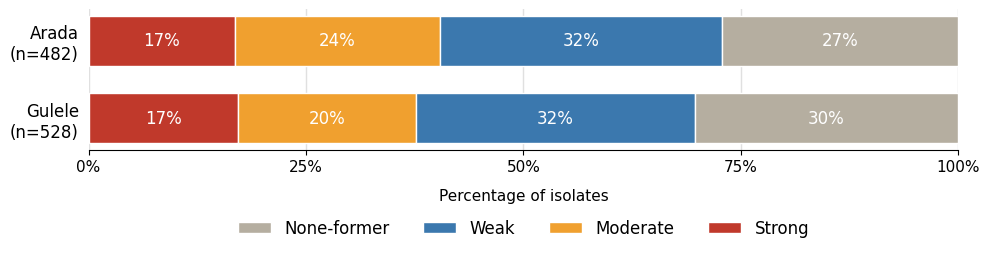

In [57]:

# Replace these with your actual column names:
group_col = "Sub City"           
category_col = "Category" # e.g. "Non-former" / "Weak" / "Moderate" / "Strong"

# -------------------------------------------------------------------
# Build a percentage cross-tab: rows = group, columns = category
# -------------------------------------------------------------------
cat_order = ["None-former", "Weak", "Moderate", "Strong"]
group_order = ["Arada", "Gulele"]  # top-to-bottom order desired

counts = pd.crosstab(df[group_col], df[category_col])
counts = counts.reindex(index=group_order, columns=cat_order)

n_per_group = counts.sum(axis=1)
pct = counts.div(n_per_group, axis=0) * 100

# -------------------------------------------------------------------
# Plot as a 100% stacked horizontal bar chart
# Segment order left-to-right: Strong, Moderate, Weak, None-former
# -------------------------------------------------------------------
plot_order = ["Strong", "Moderate", "Weak", "None-former"]
colors = {
    "Strong": "#c0392b",
    "Moderate": "#f0a02f",
    "Weak": "#3b78ae",
    "None-former": "#b5aea0",
}

# y positions: reverse so first group in group_order appears at the top
groups = list(pct.index)
y_pos = list(range(len(groups)))[::-1]

fig, ax = plt.subplots(figsize=(10, 3))

left = [0] * len(groups)
for cat in plot_order:
    values = pct[cat].values
    bars = ax.barh(
        y_pos, values, left=left,
        color=colors[cat], edgecolor="white", height=0.65,
        label=cat, zorder=3
    )
    # Add percentage labels inside each segment
    for y, val, l in zip(y_pos, values, left):
        if val >= 3:  # skip tiny segments to avoid clutter
            ax.text(
                l + val / 2, y, f"{val:.0f}%",
                ha="center", va="center",
                color="white", fontsize=12, fontweight="regular"
            )
    left = [l + v for l, v in zip(left, values)]

# -------------------------------------------------------------------
# Axis / label formatting
# -------------------------------------------------------------------
labels = [f"{g}\n(n={n_per_group[g]})" for g in groups]
ax.set_yticks(y_pos)
ax.set_yticklabels(labels, fontsize=12)

ax.set_xlim(0, 100)
ax.set_xticks([0, 25, 50, 75, 100])
ax.set_xticklabels(["0%", "25%", "50%", "75%", "100%"], fontsize=11)
ax.set_xlabel("Percentage of isolates", fontsize=11, labelpad=10)

# Light vertical gridlines behind bars
ax.xaxis.grid(True, color="#e0e0e0", linewidth=1, zorder=0)
ax.set_axisbelow(True)

# Remove spines for a clean look
for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)
ax.tick_params(left=False)

# -------------------------------------------------------------------
# Legend at the bottom, ordered None-former, Weak, Moderate, Strong
# -------------------------------------------------------------------
handles, labels_leg = ax.get_legend_handles_labels()
legend_order = ["None-former", "Weak", "Moderate", "Strong"]
ordered = [(handles[labels_leg.index(l)], l) for l in legend_order]
ax.legend(
    [h for h, l in ordered], [l for h, l in ordered],
    loc="upper center", bbox_to_anchor=(0.5, -0.39),
    ncol=4, frameon=False, fontsize=12
)

plt.tight_layout()
plt.show()

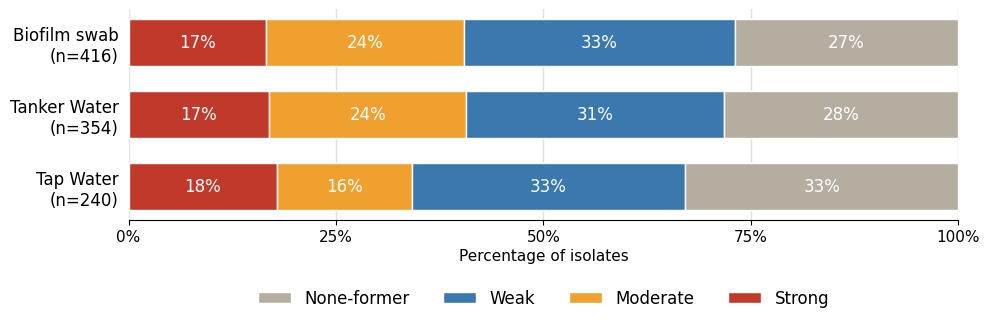

In [58]:


# Replace these with your actual column names:
group_col = "sample_type"              # e.g. "Biofilm" / "Tanker Water" / "Tap Water"
category_col = "Category" # e.g. "Non-former" / "Weak" / "Moderate" / "Strong"

# -------------------------------------------------------------------
# Build a percentage cross-tab: rows = group, columns = category
# -------------------------------------------------------------------
cat_order = ["None-former", "Weak", "Moderate", "Strong"]
group_order = ["Biofilm swab", "Tanker Water", "Tap Water"]  # top-to-bottom order desired

counts = pd.crosstab(df[group_col], df[category_col])
counts = counts.reindex(index=group_order, columns=cat_order)

n_per_group = counts.sum(axis=1)
pct = counts.div(n_per_group, axis=0) * 100

# -------------------------------------------------------------------
# Plot as a 100% stacked horizontal bar chart
# Segment order left-to-right: Strong, Moderate, Weak, None-former
# -------------------------------------------------------------------
plot_order = ["Strong", "Moderate", "Weak", "None-former"]
colors = {
    "Strong": "#c0392b",
    "Moderate": "#f0a02f",
    "Weak": "#3b78ae",
    "None-former": "#b5aea0",
}

# y positions: reverse so first group in group_order appears at the top
groups = list(pct.index)
y_pos = list(range(len(groups)))[::-1]

fig, ax = plt.subplots(figsize=(10, 3.5))

left = [0] * len(groups)
for cat in plot_order:
    values = pct[cat].values
    bars = ax.barh(
        y_pos, values, left=left,
        color=colors[cat], edgecolor="white", height=0.65,
        label=cat, zorder=3
    )
    # Add percentage labels inside each segment
    for y, val, l in zip(y_pos, values, left):
        if val >= 3:  # skip tiny segments to avoid clutter
            ax.text(
                l + val / 2, y, f"{val:.0f}%",
                ha="center", va="center",
                color="white", fontsize=12, fontweight="regular"
            )
    left = [l + v for l, v in zip(left, values)]

# -------------------------------------------------------------------
# Axis / label formatting
# -------------------------------------------------------------------
labels = [f"{g}\n(n={n_per_group[g]})" for g in groups]
ax.set_yticks(y_pos)
ax.set_yticklabels(labels, fontsize=12)

ax.set_xlim(0, 100)
ax.set_xticks([0, 25, 50, 75, 100])
ax.set_xticklabels(["0%", "25%", "50%", "75%", "100%"], fontsize=11)
ax.set_xlabel("Percentage of isolates", fontsize=11, labelpad=3)

# Light vertical gridlines behind bars
ax.xaxis.grid(True, color="#e0e0e0", linewidth=1, zorder=0)
ax.set_axisbelow(True)

# Remove spines for a clean look
for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)
ax.tick_params(left=False)

# -------------------------------------------------------------------
# Legend at the bottom, ordered None-former, Weak, Moderate, Strong
# -------------------------------------------------------------------
handles, labels_leg = ax.get_legend_handles_labels()
legend_order = ["None-former", "Weak", "Moderate", "Strong"]
ordered = [(handles[labels_leg.index(l)], l) for l in legend_order]
ax.legend(
    [h for h, l in ordered], [l for h, l in ordered],
    loc="upper center", bbox_to_anchor=(0.5, -0.26),
    ncol=4, frameon=False, fontsize=12
)

plt.tight_layout()
plt.show()

In [59]:

import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.miscmodels.ordinal_model import OrderedModel

# =====================================================================
# 1. LOAD DATA
# =====================================================================
file_path = "biofilmFINAL_clean.xlsx"   # update path as needed
df = pd.read_excel(file_path, sheet_name="Sheet1")  # adjust sheet name if needed

print(df.shape)
print(df.columns.tolist())

# =====================================================================
# 2. SET UP VARIABLES
# =====================================================================
# Category as an ordered categorical variable
cat_order = ["None-former", "Weak", "Moderate", "Strong"]
df["Category"] = pd.Categorical(df["Category"], categories=cat_order, ordered=True)

# Positive biofilm former = anything other than "None-former"
df["Positive"] = np.where(df["Category"] == "None-former", 0, 1)

# Set reference levels to match your table
# Sample Type: Biofilm swab = reference
df["sample_type"] = pd.Categorical(
    df["sample_type"],
    categories=["Biofilm swab", "Tanker Water", "Tap Water"],   # update labels to match your actual values
    ordered=False
)
# Sub City: Arada = reference
df["Sub City"] = pd.Categorical(
    df["Sub City"],
    categories=["Arada", "Gulele"],
    ordered=False
)

# =====================================================================
# 3. DESCRIPTIVE STATISTICS (n, Positive n%, Mean/Median OD-ODc)
# =====================================================================
def describe_group(data, group_col):
    rows = []
    for level, g in data.groupby(group_col, observed=True):
        n = len(g)
        pos_n = g["Positive"].sum()
        pos_pct = pos_n / n * 100
        mean_od = g["OD - ODc"].mean()
        median_od = g["OD - ODc"].median()
        rows.append({
            group_col: level,
            "n": n,
            "Positive_n": pos_n,
            "Positive_pct": round(pos_pct, 1),
            "Mean_OD_ODc": round(mean_od, 3),
            "Median_OD_ODc": round(median_od, 3)
        })
    return pd.DataFrame(rows)

desc_sampletype = describe_group(df, "sample_type")
desc_subcity = describe_group(df, "Sub City")

print("\n--- Descriptives by Sample Type ---")
print(desc_sampletype)
print("\n--- Descriptives by Sub City ---")
print(desc_subcity)

# =====================================================================
# 4. ORDINAL LOGISTIC REGRESSION (proportional odds model)
#    Category ~ Sample Type + Sub City
# =====================================================================
# Build design matrix (drop first level = reference, matches table)
X_ord = pd.get_dummies(
    df[["sample_type", "Sub City"]],
    drop_first=True
).astype(float)
y_ord = df["Category"]

ord_model = OrderedModel(y_ord, X_ord, distr="logit")
ord_result = ord_model.fit(method="bfgs", disp=False)
print("\n--- Ordinal Logistic Regression Summary ---")
print(ord_result.summary())

# Extract OR, 95% CI, p-values for the predictor terms only
# (exclude the threshold/cutpoint parameters, which statsmodels labels e.g. "None-former/Weak")
params = ord_result.params
conf = ord_result.conf_int()
pvals = ord_result.pvalues

predictor_names = X_ord.columns.tolist()
ord_summary = pd.DataFrame({
    "Term": predictor_names,
    "OR": np.exp(params[predictor_names]),
    "CI_lower": np.exp(conf.loc[predictor_names, 0]),
    "CI_upper": np.exp(conf.loc[predictor_names, 1]),
    "p_value": pvals[predictor_names]
}).reset_index(drop=True)

print("\n--- Ordinal Model: Odds Ratios ---")
print(ord_summary)

# =====================================================================
# 5. LINEAR MIXED MODEL
#    OD - ODc ~ Sample Type + Sub City, random intercept for Household ID
# =====================================================================
lmm_model = smf.mixedlm(
    "Q('OD - ODc') ~ C(Q('sample_type'), Treatment(reference='Biofilm swab')) "
    "+ C(Q('Sub City'), Treatment(reference='Arada'))",
    data=df,
    groups=df["Household ID"]
)
lmm_result = lmm_model.fit(reml=True)
print("\n--- Linear Mixed Model Summary ---")
print(lmm_result.summary())

# Extract beta, 95% CI, p-values for fixed effects (excluding intercept and random-effect variance)
lmm_params = lmm_result.params
lmm_conf = lmm_result.conf_int()
lmm_pvals = lmm_result.pvalues

fixed_terms = [t for t in lmm_params.index if t not in ("Intercept", "Group Var")]
lmm_summary = pd.DataFrame({
    "Term": fixed_terms,
    "Beta": lmm_params[fixed_terms].round(3),
    "CI_lower": lmm_conf.loc[fixed_terms, 0].round(3),
    "CI_upper": lmm_conf.loc[fixed_terms, 1].round(3),
    "p_value": lmm_pvals[fixed_terms].round(3)
}).reset_index(drop=True)

print("\n--- LMM: Fixed Effects (Beta) ---")
print(lmm_summary)

# =====================================================================
# 6. EXPORT COMBINED SUMMARY TABLE
# =====================================================================
with pd.ExcelWriter("biofilm_regression_results.xlsx") as writer:
    desc_sampletype.to_excel(writer, sheet_name="Descriptives_SampleType", index=False)
    desc_subcity.to_excel(writer, sheet_name="Descriptives_SubCity", index=False)
    ord_summary.to_excel(writer, sheet_name="Ordinal_Model_OR", index=False)
    lmm_summary.to_excel(writer, sheet_name="LMM_Beta", index=False)

print("\nSaved results to biofilm_regression_results.xlsx")

(1010, 21)
['Sample ID', 'Household ID', 'Sample Code', 'sample_type', 'Sub City', 'Site Type', 'Tank', 'Plate', 'Position', 'OD 1', 'OD 2', 'Mean OD', 'Normalized OD', 'OD - ODc', 'NC', 'NC Mean', 'NC SD', 'ODc (Cutoff)', '2×ODc (Weak)', '4×ODc (Moderate)', 'Category']

--- Descriptives by Sample Type ---
    sample_type    n  Positive_n  Positive_pct  Mean_OD_ODc  Median_OD_ODc
0  Biofilm swab  416         304          73.1        0.204          0.070
1  Tanker Water  354         254          71.8        0.259          0.072
2     Tap Water  240         161          67.1        0.238          0.041

--- Descriptives by Sub City ---
  Sub City    n  Positive_n  Positive_pct  Mean_OD_ODc  Median_OD_ODc
0    Arada  482         351          72.8        0.262          0.078
1   Gulele  528         368          69.7        0.203          0.055

--- Ordinal Logistic Regression Summary ---
                             OrderedModel Results                             
Dep. Variable:          

C:\Users\elsab\AppData\Roaming\Python\Python313\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
C:\Users\elsab\AppData\Roaming\Python\Python313\site-packages\statsmodels\regression\mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(



--- Linear Mixed Model Summary ---
                                       Mixed Linear Model Regression Results
Model:                                MixedLM                   Dependent Variable:                   Q('OD - ODc')
No. Observations:                     1010                      Method:                               REML         
No. Groups:                           132                       Scale:                                0.1715       
Min. group size:                      2                         Log-Likelihood:                       -606.1189    
Max. group size:                      16                        Converged:                            Yes          
Mean group size:                      7.7                                                                          
-------------------------------------------------------------------------------------------------------------------
                                                                         Co

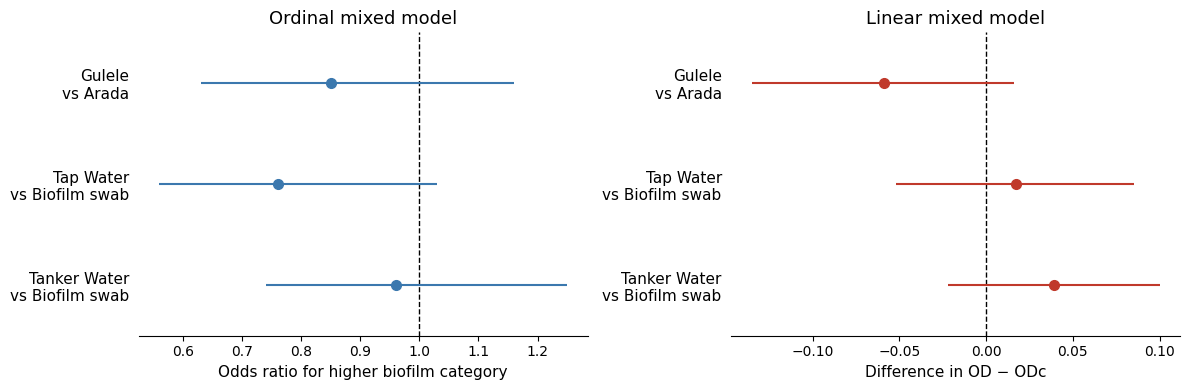

In [60]:

# --- Ordinal mixed model: Odds Ratios ---
ord_data = pd.DataFrame({
    "Term": ["Gulele\nvs Arada", "Tap Water\nvs Biofilm swab", "Tanker Water\nvs Biofilm swab"],
    "Estimate": [0.85, 0.76, 0.96],
    "CI_lower": [0.63, 0.56, 0.74],
    "CI_upper": [1.16, 1.03, 1.25],
})

# --- Linear mixed model: Beta (difference in OD - ODc) ---
lmm_data = pd.DataFrame({
    "Term": ["Gulele\nvs Arada", "Tap Water\nvs Biofilm swab", "Tanker Water\nvs Biofilm swab"],
    "Estimate": [-0.059, 0.017, 0.039],
    "CI_lower": [-0.135, -0.052, -0.022],
    "CI_upper": [0.016, 0.085, 0.1],
})

# =====================================================================
# 2. PLOT
# =====================================================================
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

y_pos = list(range(len(ord_data)))[::-1]  # top-to-bottom order

# ---------------------------------------------------------------
# Panel 1: Ordinal mixed model (Odds Ratios)
# ---------------------------------------------------------------
ax1 = axes[0]
ax1.errorbar(
    ord_data["Estimate"], y_pos,
    xerr=[ord_data["Estimate"] - ord_data["CI_lower"],
          ord_data["CI_upper"] - ord_data["Estimate"]],
    fmt="o", color="#3b78ae", ecolor="#3b78ae",
    elinewidth=1.5, capsize=0, markersize=7, zorder=3
)
ax1.axvline(1, color="black", linestyle="--", linewidth=1, zorder=1)
ax1.set_yticks(y_pos)
ax1.set_yticklabels(ord_data["Term"], fontsize=11)
ax1.set_xlabel("Odds ratio for higher biofilm category", fontsize=11)
ax1.set_title("Ordinal mixed model", fontsize=13)
ax1.set_ylim(-0.5, len(ord_data) - 0.5)

# ---------------------------------------------------------------
# Panel 2: Linear mixed model (Beta)
# ---------------------------------------------------------------
ax2 = axes[1]
ax2.errorbar(
    lmm_data["Estimate"], y_pos,
    xerr=[lmm_data["Estimate"] - lmm_data["CI_lower"],
          lmm_data["CI_upper"] - lmm_data["Estimate"]],
    fmt="o", color="#c0392b", ecolor="#c0392b",
    elinewidth=1.5, capsize=0, markersize=7, zorder=3
)
ax2.axvline(0, color="black", linestyle="--", linewidth=1, zorder=1)
ax2.set_yticks(y_pos)
ax2.set_yticklabels(lmm_data["Term"], fontsize=11)
ax2.set_xlabel("Difference in OD − ODc", fontsize=11)
ax2.set_title("Linear mixed model", fontsize=13)
ax2.set_ylim(-0.5, len(lmm_data) - 0.5)

# ---------------------------------------------------------------
# Shared formatting
# ---------------------------------------------------------------
for ax in axes:
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)
    ax.tick_params(left=False)
    ax.spines["left"].set_visible(False)

plt.tight_layout()
plt.savefig("biofilm_forest_plot.png", dpi=300, bbox_inches="tight")
plt.show()

In [61]:
import re

In [62]:

import re
import statsmodels.formula.api as smf

biofilm_path = "biofilmFINAL_clean.xlsx"
physchem_path = "cleanclean_phy.xlsx"
survey_path = "Finalsurvay.xlsx"

biofilm_df = pd.read_excel(biofilm_path)
physchem_df = pd.read_excel(physchem_path)
survey_df = pd.read_excel(survey_path)

physchem_df = physchem_df.rename(
    columns={"Temprature": "Temperature"}
)
print("Biofilm:", biofilm_df.shape)
print("Physicochemical:", physchem_df.shape)
print("Survey:", survey_df.shape)

Biofilm: (1010, 21)
Physicochemical: (269, 17)
Survey: (132, 18)


In [63]:
def standardize_household_id(series):

    x = (
        series.astype(str)
        .str.strip()
        .str.upper()
        .str.replace(r"[^A-Z0-9]", "", regex=True)
    )

    # Convert HOUSE to HOUSEHOLD where needed
    x = x.str.replace(
        r"^(ARADA|GULELE)HOUSE(\d+)$",
        r"\1HOUSEHOLD\2",
        regex=True
    )

    return x


biofilm_df["Household ID"] = standardize_household_id(
    biofilm_df["Household ID"]
)

physchem_df["Household ID"] = standardize_household_id(
    physchem_df["Household ID"]
)

survey_df["Household ID"] = standardize_household_id(
    survey_df["Household ID"]
)

print("Household IDs standardized.")

Household IDs standardized.


In [64]:
supply_freq_map = {
    "daily": 7,
    "every day": 7,
    "6 days a week": 6,
    "5 days a week": 5,
    "4 days a week": 4,
    "3 days a week": 3,
    "2 days a week": 2,
    "twice a week": 2,
    "once a week": 1,
    "once every two weeks": 0.5,
    "once in two weeks": 0.5,
    "within two weeks": 0.5,
    "1-2 days in week": 1.5,
    "3-5 days in week": 4,
    "once a month": 0.23,
    "rarely": 0.1,
    "never": 0
}


def parse_frequency_to_per_week(text):

    if pd.isna(text):
        return np.nan

    t = str(text).strip().lower()

    if t in supply_freq_map:
        return supply_freq_map[t]

    m = re.search(
        r"(\d+(?:\.\d+)?)\s*-\s*(\d+(?:\.\d+)?)\s*(?:days?|times?).*week",
        t
    )

    if m:
        return (float(m.group(1)) + float(m.group(2))) / 2

    m = re.search(
        r"(\d+(?:\.\d+)?)\s*(?:times?|days?)\s*(?:a|/|per|in)?\s*week",
        t
    )

    if m:
        return float(m.group(1))

    return np.nan


survey_df["Water Supply days per week"] = (
    survey_df["Water supply frequency"]
    .apply(parse_frequency_to_per_week)
)

print(
    survey_df[
        [
            "Water supply frequency",
            "Water Supply days per week"
        ]
    ].head(20)
)

   Water supply frequency  Water Supply days per week
0        1-2 days in week                         1.5
1        3-5 days in week                         4.0
2        3-5 days in week                         4.0
3        3-5 days in week                         4.0
4        3-5 days in week                         4.0
5        3-5 days in week                         4.0
6        1-2 days in week                         1.5
7        1-2 days in week                         1.5
8        3-5 days in week                         4.0
9        1-2 days in week                         1.5
10       1-2 days in week                         1.5
11       3-5 days in week                         4.0
12       3-5 days in week                         4.0
13       3-5 days in week                         4.0
14                  Daily                         7.0
15       3-5 days in week                         4.0
16       3-5 days in week                         4.0
17       3-5 days in week   

In [65]:
cleaning_freq_map = {
    "weekly": 52,
    "monthly": 12,
    "every month": 12,
    "every two weeks": 26,
    "twice a month": 24,
    "every 3 months": 4,
    "3 month": 4,
    "every 6 months": 2,
    "6 month": 2,
    "2 month": 6,
    "twice a year": 2,
    "once a year": 1,
    "annually": 1,
    "two years": 0.5,
    "never": 0,
    "not applicable": np.nan
}


def parse_cleaning_to_per_year(text):

    if pd.isna(text):
        return np.nan

    t = str(text).strip().lower()

    if t in cleaning_freq_map:
        return cleaning_freq_map[t]

    m = re.search(r"every\s*(\d+(?:\.\d+)?)\s*weeks?", t)

    if m:
        return 52 / float(m.group(1))

    m = re.search(r"every\s*(\d+(?:\.\d+)?)\s*months?", t)

    if m:
        return 12 / float(m.group(1))

    m = re.search(r"(\d+(?:\.\d+)?)\s*months?$", t)

    if m:
        return 12 / float(m.group(1))

    m = re.search(r"every\s*(\d+(?:\.\d+)?)\s*years?", t)

    if m:
        return 1 / float(m.group(1))

    m = re.search(r"(\d+(?:\.\d+)?)\s*years?$", t)

    if m:
        return 1 / float(m.group(1))

    return np.nan


survey_df["Cleaning frequency per year"] = (
    survey_df["Tanker cleaning frequency"]
    .apply(parse_cleaning_to_per_year)
)

print(
    survey_df[
        [
            "Tanker cleaning frequency",
            "Cleaning frequency per year"
        ]
    ].head(20)
)

   Tanker cleaning frequency  Cleaning frequency per year
0                      never                          0.0
1                     weekly                         52.0
2                      never                          0.0
3                    monthly                         12.0
4                      never                          0.0
5                        NaN                          NaN
6                      never                          0.0
7                Once a year                          1.0
8                    6 month                          2.0
9                        NaN                          NaN
10                   monthly                         12.0
11               Once a year                          1.0
12                       NaN                          NaN
13                     never                          0.0
14                   3 month                          4.0
15                   6 month                          2.0
16            

In [66]:
def safe_parse_date(value):

    if pd.isna(value):
        return pd.NaT

    try:
        return pd.to_datetime(
            value,
            dayfirst=True
        )

    except (ValueError, TypeError):
        return pd.NaT


def parse_tank_age_years(installed_text, interview_date):

    if pd.isna(installed_text):
        return np.nan

    t = str(installed_text).strip().lower()

    interview_dt = safe_parse_date(interview_date)

    if pd.notna(interview_dt):
        ref_year = interview_dt.year
    else:
        ref_year = pd.Timestamp.now().year

    # 4-digit installation year
    m = re.search(r"(?:19|20)\d{2}", t)

    if m:
        installed_year = int(m.group())
        return max(ref_year - installed_year, 0)

    # Before two years
    if re.search(r"before\s+two\s+years?", t):
        return 2

    # Before one year
    if re.search(r"before\s+(?:one|1)\s+year", t):
        return 1

    # Before one month
    if re.search(r"before\s+(?:one|1)\s+month", t):
        return 1 / 12

    # X years ago
    m = re.search(
        r"(\d+(?:\.\d+)?)\s*years?\s*(?:ago)?",
        t
    )

    if m:
        return float(m.group(1))

    # X months ago
    m = re.search(
        r"(\d+(?:\.\d+)?)\s*months?\s*(?:ago)?",
        t
    )

    if m:
        return float(m.group(1)) / 12

    return np.nan


survey_df["Tank age years"] = survey_df.apply(
    lambda row: parse_tank_age_years(
        row["When tanker was installed"],
        row["Date"]
    ),
    axis=1
)

print(
    survey_df[
        [
            "When tanker was installed",
            "Tank age years"
        ]
    ].tail(20)
)

    When tanker was installed  Tank age years
112                       NaN             NaN
113          Before two years             2.0
114          Before two years             2.0
115                   5 years             5.0
116                   7 years             7.0
117          Before two years             2.0
118                   6 years             6.0
119                    4 year             4.0
120          Before two years             2.0
121                  10 years            10.0
122                   6 years             6.0
123                    5years             5.0
124                       NaN             NaN
125          Before two years             2.0
126                  12 years            12.0
127                  10 years            10.0
128                       NaN             NaN
129          Before two years             2.0
130                       NaN             NaN
131                  10 years            10.0


In [67]:
survey_predictors = [
    "Water Supply days per week",
    "Cleaning frequency per year",
    "Tank age years"
]

print(
    survey_df[survey_predictors]
    .isna()
    .sum()
)

Water Supply days per week      1
Cleaning frequency per year     8
Tank age years                 23
dtype: int64


In [68]:
physchem_use = physchem_df[
    [
        "Household ID",
        "pH",
        "Temperature",
        "Turbidity"
    ]
].copy()

for col in ["pH", "Temperature", "Turbidity"]:
    physchem_use[col] = pd.to_numeric(
        physchem_use[col],
        errors="coerce"
    )

physchem_use = (
    physchem_use
    .groupby(
        "Household ID",
        as_index=False
    )
    .mean()
)

print(physchem_use.shape)
print(
    "Physicochemical households:",
    physchem_use["Household ID"].nunique()
)

(132, 4)
Physicochemical households: 132


In [69]:
biofilm_use = biofilm_df[["Sample ID", "Household ID", "sample_type", "Sub City", "OD - ODc"]].copy()
 
# --- Physicochemical: aggregate to household level (269 rows -> per household mean) ---
physchem_df = physchem_df.rename(columns={"Temprature": "Temperature"})
physchem_use = physchem_df[["Household ID", "pH", "Temperature", "Turbidity"]].copy()
physchem_use = physchem_use.groupby("Household ID", as_index=False).mean(numeric_only=True)


In [70]:
survey_use = survey_df[[
    "Household ID",
    "Water Supply days per week",
    "Cleaning frequency per year",
    "Tank age years"
]].copy()

In [71]:
merged = biofilm_use.merge(
    physchem_use,
    on="Household ID",
    how="left"
)

merged = merged.merge(
    survey_use,
    on="Household ID",
    how="left"
)

print("Merged dataset shape:", merged.shape)
print(
    "Unique households:",
    merged["Household ID"].nunique()
)

Merged dataset shape: (1010, 11)
Unique households: 132


In [72]:
model_vars = [
    "OD - ODc",
    "Household ID",
    "Water Supply days per week",
    "Cleaning frequency per year",
    "Tank age years",
    "pH",
    "Temperature",
    "Turbidity"
]

print(
    merged[model_vars]
    .isna()
    .sum()
    .sort_values(ascending=False)
)

Tank age years                 170
Cleaning frequency per year     65
Water Supply days per week       9
Household ID                     0
OD - ODc                         0
pH                               0
Temperature                      0
Turbidity                        0
dtype: int64


In [73]:
# =====================================================================
# STEP 15: CREATE COMPLETE-CASE DATASET FOR THE LMM
# =====================================================================

model_vars = [
    "OD - ODc",
    "Household ID",
    "Water Supply days per week",
    "Cleaning frequency per year",
    "Tank age years",
    "pH",
    "Temperature",
    "Turbidity"
]

model_df = (
    merged[model_vars]
    .dropna()
    .copy()
)

print(
    f"Isolates available for modeling: "
    f"{len(model_df)} of {len(merged)}"
)

print(
    f"Households available for modeling: "
    f"{model_df['Household ID'].nunique()} "
    f"of {merged['Household ID'].nunique()}"
)

Isolates available for modeling: 792 of 1010
Households available for modeling: 103 of 132


In [74]:
model_df.to_excel(
    "predictive_lmm_model_data.xlsx",
    index=False
)


In [75]:
# =====================================================================
# STEP 16: CHECK CLUSTER SIZES
# =====================================================================

household_counts = model_df["Household ID"].value_counts()

print("Number of households:", model_df["Household ID"].nunique())

print("\nIsolates per household:")
print(household_counts.describe())

print("\nSmallest household clusters:")
print(household_counts.sort_values().head(10))

Number of households: 103

Isolates per household:
count    103.000000
mean       7.689320
std        2.797159
min        2.000000
25%        6.000000
50%        8.000000
75%        9.000000
max       16.000000
Name: count, dtype: float64

Smallest household clusters:
Household ID
GULELEHOUSEHOLD8     2
GULELEHOUSEHOLD5     2
ARADAHOUSEHOLD46     3
ARADAHOUSEHOLD45     3
GULELEHOUSEHOLD38    3
GULELEHOUSEHOLD45    4
GULELEHOUSEHOLD52    4
ARADAHOUSEHOLD35     4
GULELEHOUSEHOLD60    4
ARADAHOUSEHOLD27     4
Name: count, dtype: int64


In [76]:
# =====================================================================
# STEP 17: CHECK PREDICTOR VARIATION
# =====================================================================

predictors = [
    "Water Supply days per week",
    "Cleaning frequency per year",
    "Tank age years",
    "pH",
    "Temperature",
    "Turbidity"
]

print(
    model_df[predictors]
    .agg(["count", "nunique", "mean", "std", "min", "max"])
    .T
)

                             count  nunique       mean        std        min  \
Water Supply days per week   792.0      4.0   3.892045   2.049180   0.500000   
Cleaning frequency per year  792.0      8.0   4.414141  10.442223   0.000000   
Tank age years               792.0     15.0   4.315341   5.145458   0.083333   
pH                           792.0     89.0   7.855901   0.347801   6.705000   
Temperature                  792.0     75.0  16.614310   2.098564  11.000000   
Turbidity                    792.0      6.0   0.332702   0.888601   0.000000   

                                max  
Water Supply days per week    7.000  
Cleaning frequency per year  52.000  
Tank age years               40.000  
pH                            8.685  
Temperature                  25.500  
Turbidity                     4.000  


In [77]:
# =====================================================================
# STEP 18: CHECK PREDICTOR CORRELATIONS
# =====================================================================

correlation_matrix = model_df[
    [
        "Water Supply days per week",
        "Cleaning frequency per year",
        "Tank age years",
        "pH",
        "Temperature",
        "Turbidity"
    ]
].corr()

print(
    correlation_matrix
    .round(3)
)

                             Water Supply days per week  \
Water Supply days per week                        1.000   
Cleaning frequency per year                      -0.075   
Tank age years                                   -0.175   
pH                                                0.144   
Temperature                                      -0.085   
Turbidity                                        -0.121   

                             Cleaning frequency per year  Tank age years  \
Water Supply days per week                        -0.075          -0.175   
Cleaning frequency per year                        1.000          -0.055   
Tank age years                                    -0.055           1.000   
pH                                                -0.157           0.051   
Temperature                                        0.131           0.055   
Turbidity                                         -0.045          -0.009   

                                pH  Temperature  Turb

In [78]:
var_household = float(lmm_result.cov_re.iloc[0, 0])
var_resid = lmm_result.scale
icc = var_household / (var_household + var_resid)

print(f"Household variance: {var_household:.6f}")
print(f"Residual variance:  {var_resid:.6f}")
print(f"ICC: {icc:.4f}")

Household variance: 0.030318
Residual variance:  0.171459
ICC: 0.1503


In [79]:

formula = (
    "Q('OD - ODc') ~ "
    "Q('Water Supply days per week') + "
    "Q('Cleaning frequency per year') + "
    "Q('Tank age years') + "
    "pH + Temperature + Turbidity"
)

lmm_model = smf.mixedlm(
    formula,
    data=model_df,
    groups=model_df["Household ID"]
)

# Fix: pre-fit with ML to get stable starting values, then refit with REML
ml_fit = lmm_model.fit(reml=False, method="powell")
lmm_result = lmm_model.fit(reml=True, method="lbfgs", start_params=ml_fit.params)

print(lmm_result.summary())
print("Converged:", lmm_result.converged)

# ---- Format as a clean fixed-effects table ----
def stars(p):
    if p < 0.001: return "***"
    if p < 0.01:  return "**"
    if p < 0.05:  return "*"
    return ""

ci = lmm_result.conf_int()
table = pd.DataFrame({
    "β": lmm_result.fe_params,
    "CI_low": ci[0],
    "CI_high": ci[1],
    "P value": lmm_result.pvalues[lmm_result.fe_params.index]
})



                   Mixed Linear Model Regression Results
Model:                  MixedLM      Dependent Variable:      Q('OD - ODc')
No. Observations:       792          Method:                  REML         
No. Groups:             103          Scale:                   0.1857       
Min. group size:        2            Log-Likelihood:          -513.9906    
Max. group size:        16           Converged:               Yes          
Mean group size:        7.7                                                
---------------------------------------------------------------------------
                                 Coef.  Std.Err.   z    P>|z| [0.025 0.975]
---------------------------------------------------------------------------
Intercept                        -1.998    0.574 -3.483 0.000 -3.123 -0.874
Q('Water Supply days per week')  -0.006    0.011 -0.549 0.583 -0.029  0.016
Q('Cleaning frequency per year') -0.001    0.002 -0.306 0.759 -0.005  0.004
Q('Tank age years')            

In [80]:
import pandas as pd

# 1. Load the data (use the full path if the file isn't in the same folder)
df = pd.read_excel("malditof _final_1.xlsx")

# 2. Clean stray spaces in the text columns
df["Identified Organism"] = df["Identified Organism"].str.strip()
df["cata"] = df["cata"].str.strip()

# 3. Keep only the category name: "Strong (S)" -> "Strong"
df["Biofilm category"] = df["cata"].str.replace(r"\s*\(.*\)", "", regex=True)

# 4. The order you want the categories to appear in
order = ["None", "Weak", "Moderate", "Strong"]

# 5. Count each category per organism
counts = (
    df.groupby(["Identified Organism", "Biofilm category"])
      .size()
      .unstack(fill_value=0)
      .reindex(columns=order, fill_value=0)
)

# 6. Build the table: total n + the formatted breakdown
table = pd.DataFrame({"n": counts.sum(axis=1)})
table["Biofilm category"] = counts.apply(
    lambda row: ", ".join(f"{cat} ({row[cat]})" for cat in order if row[cat] > 0),
    axis=1,
)

# 7. Sort by n (largest first), then alphabetically
table = table.reset_index().sort_values(
    ["n", "Identified Organism"], ascending=[False, True]
)

print(table.to_string(index=False))
table.to_excel("organism_table.xlsx", index=False)  # saves a copy you can paste into Word

             Identified Organism  n                             Biofilm category
                 Bacillus cereus 12 None (6), Weak (3), Moderate (1), Strong (2)
          Pseudomonas aeruginosa  8 None (1), Weak (1), Moderate (2), Strong (4)
             Delftia acidovorans  6                         Weak (1), Strong (5)
               Bacillus subtilis  3                     Moderate (1), Strong (2)
           Bacillus vallismortis  3           Weak (1), Moderate (1), Strong (1)
          Bacillus licheniformis  2                     Moderate (1), Strong (1)
       Providencia alcalifaciens  2                       Weak (1), Moderate (1)
           Pseudomonas monteilii  2                       Weak (1), Moderate (1)
Aneurinibacillus aneurinilyticus  1                                   Strong (1)
          Bacillus thuringiensis  1                                     None (1)
        Leclercia adecarboxylata  1                                   Strong (1)
            Raoultella terri